# 체험 전환 예측 — 전체 파이프라인

구조: 환경설정 → 데이터 로드 → 전처리 → EDA → 피처 엔지니어링 → **Train/Valid/Test 분할** → 모델링 → Threshold 튜닝(Valid) → 최종 평가(Test)

> 변수명 규칙: 실험 단계별로 접미사를 분리해 충돌을 방지함 (`_base`, `_v2`, `_tuned` 등)

# 1. 환경설정

In [ ]:
!pip install -q gdown koreanize-matplotlib

import gdown

files = {
    "site_area.csv": "1tqjCywUBX7ivID62rDJ19ZchQmkLmCmr",
    "trial_access_log.csv": "17_VUATpRUGn7wcmkUkUcFmUQmkA9S0wb",
    "trial_payment.csv": "1OM2pDtVaq6vG-JcoilOunfETUtdLeZWN",
    "trial_register.csv": "1zbjXQMB6jJzJa0seEL0jUwuiRCYGQXFl",
    "trial_visit_info.csv": "1-hNqJ1aoHfqaDJV-WaLsXvf6nk_BNUD0"
}

for filename, file_id in files.items():
    gdown.download(f"https://drive.google.com/uc?id={file_id}", filename, quiet=False)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 28.1 MB/s eta 0:00:00


Downloading...
From: https://drive.google.com/uc?id=1tqjCywUBX7ivID62rDJ19ZchQmkLmCmr
To: /content/site_area.csv
100%|██████████| 81.0/81.0 [00:00<00:00, 204kB/s]
Downloading...
From: https://drive.google.com/uc?id=17_VUATpRUGn7wcmkUkUcFmUQmkA9S0wb
To: /content/trial_access_log.csv
100%|██████████| 4.81M/4.81M [00:00<00:00, 48.4MB/s]
Downloading...
From: https://drive.google.com/uc?id=1OM2pDtVaq6vG-JcoilOunfETUtdLeZWN
To: /content/trial_payment.csv
100%|██████████| 377k/377k [00:00<00:00, 50.0MB/s]
Downloading...
From: https://drive.google.com/uc?id=1zbjXQMB6jJzJa0seEL0jUwuiRCYGQXFl
To: /content/trial_register.csv
100%|██████████| 464k/464k [00:00<00:00, 46.2MB/s]
Downloading...
From: https://drive.google.com/uc?id=1-hNqJ1aoHfqaDJV-WaLsXvf6nk_BNUD0
To: /content/trial_visit_info.csv
100%|██████████| 1.40M/1.40M [00:00<00:00, 77.0MB/s]


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import koreanize_matplotlib

pd.set_option('display.max_columns', None)

area_df = pd.read_csv('site_area.csv')
access_log_df = pd.read_csv('trial_access_log.csv')
payment_log_df = pd.read_csv('trial_payment.csv')
register_df = pd.read_csv('trial_register.csv')
visit_info_df = pd.read_csv('trial_visit_info.csv')

# 2. 데이터 구조 파악

- `trial_register` : 3일체험 신청 (유저당 1회만 제공)
- `trial_visit_info` : 신청자 일자별 방문기록
- `trial_access_log` : 신청자 출입기록 (checkin: 입실=1, 퇴실=2)
- `trial_payment` : 신청자 결제 여부
- `site_area` : 지점별 면적

In [ ]:
for name, df in [('access_log', access_log_df), ('visit_info', visit_info_df),
                  ('payment_log', payment_log_df), ('register', register_df), ('area', area_df)]:
    print(f'── {name} ──')
    print(df.shape, '| 중복:', df.duplicated().sum())
    print(df.dtypes.to_dict())
    print()

── access_log ──
(63708, 5) | 중복: 359
{'id': dtype('int64'), 'checkin': dtype('int64'), 'cdate': dtype('O'), 'site_id': dtype('int64'), 'user_uuid': dtype('O')}

── visit_info ──
(11477, 7) | 중복: 48
{'site_id': dtype('int64'), 'date': dtype('O'), 'stay_time': dtype('O'), 'stay_time_second': dtype('int64'), 'first_enter_time': dtype('O'), 'last_leave_time': dtype('O'), 'user_uuid': dtype('O')}

── payment_log ──
(9659, 2) | 중복: 35
{'is_payment': dtype('int64'), 'user_uuid': dtype('O')}

── register ──
(9659, 2) | 중복: 28
{'trial_date': dtype('O'), 'user_uuid': dtype('O')}

── area ──
(9, 2) | 중복: 0
{'site_id': dtype('int64'), 'area_pyeong': dtype('int64')}



# 3. 전처리

## 3-1. 중복 제거

In [ ]:
access_log_df = access_log_df.drop_duplicates(keep='last')
visit_info_df = visit_info_df.drop_duplicates(keep='last')
payment_log_df = payment_log_df.drop_duplicates(keep='last')
register_df = register_df.drop_duplicates(keep='last')

print(access_log_df.shape, visit_info_df.shape, payment_log_df.shape, register_df.shape)

(63349, 5) (11429, 7) (9624, 2) (9631, 2)


## 3-2. 모수 설정 — register 기준, user_uuid 중복은 최신 데이터만 유지

In [ ]:
register_df = register_df.sort_values('trial_date').drop_duplicates(subset=['user_uuid'], keep='last')
print('모수:', register_df.shape, payment_log_df.shape)

모수: (9624, 2) (9624, 2)


## 3-3. datetime 타입 변환

In [ ]:
register_df['trial_date'] = pd.to_datetime(register_df['trial_date'])

access_log_df['cdate'] = pd.to_datetime(access_log_df['cdate'], utc=True).dt.tz_convert('Asia/Seoul')
access_log_df['cdate'] = pd.to_datetime(access_log_df['cdate']).dt.floor('s')

visit_info_df['first_enter_time'] = pd.to_datetime(visit_info_df['first_enter_time'], format='%Y-%m-%d %H:%M:%S', exact=False).dt.floor('s')
visit_info_df['last_leave_time'] = pd.to_datetime(visit_info_df['last_leave_time'], format='%Y-%m-%d %H:%M:%S', exact=False).dt.floor('s')
visit_info_df['stay_time'] = pd.to_timedelta(visit_info_df['stay_time']).dt.floor('s')
visit_info_df['date'] = pd.to_datetime(visit_info_df['date'])

## 3-4. visit_info 결측치를 access_log로 보강

In [ ]:
access_log_df['date'] = access_log_df['cdate'].dt.date.astype('datetime64[ns]')
access_log_df['cdate_naive'] = access_log_df['cdate'].dt.tz_localize(None)

access_first_enter = (access_log_df[access_log_df['checkin'] == 1]
    .groupby(['user_uuid', 'date'])['cdate_naive'].min().reset_index()
    .rename(columns={'cdate_naive': 'new_first_enter_time'}))

access_last_leave = (access_log_df[access_log_df['checkin'] == 2]
    .groupby(['user_uuid', 'date'])['cdate_naive'].max().reset_index()
    .rename(columns={'cdate_naive': 'new_last_leave_time'}))

visit_info_df = visit_info_df.merge(access_first_enter, on=['user_uuid', 'date'], how='left')
visit_info_df = visit_info_df.merge(access_last_leave, on=['user_uuid', 'date'], how='left')

visit_info_df['first_enter_time'] = visit_info_df['first_enter_time'].fillna(visit_info_df['new_first_enter_time'])
visit_info_df['last_leave_time'] = visit_info_df['last_leave_time'].fillna(visit_info_df['new_last_leave_time'])

visit_info_df = visit_info_df.drop(columns=['new_first_enter_time', 'new_last_leave_time'])
access_log_df = access_log_df.drop(columns=['date', 'cdate_naive'])

print(visit_info_df['first_enter_time'].isnull().sum(), visit_info_df['last_leave_time'].isnull().sum())

75 72


## 3-5. visit_info ↔ access_log 간 user_uuid 불일치 제거

In [ ]:
visit_only_uuids = set(visit_info_df['user_uuid'].unique()) - set(access_log_df['user_uuid'].unique())
access_only_uuids = set(access_log_df['user_uuid'].unique()) - set(visit_info_df['user_uuid'].unique())
uuids_to_remove = visit_only_uuids.union(access_only_uuids)

access_log_df = access_log_df[~access_log_df['user_uuid'].isin(uuids_to_remove)]
visit_info_df = visit_info_df[~visit_info_df['user_uuid'].isin(uuids_to_remove)]
payment_log_df = payment_log_df[~payment_log_df['user_uuid'].isin(uuids_to_remove)]
register_df = register_df[~register_df['user_uuid'].isin(uuids_to_remove)]

print('제거된 user_uuid 수:', len(uuids_to_remove))
print('각 df user_uuid 수:', access_log_df['user_uuid'].nunique(), visit_info_df['user_uuid'].nunique(),
      payment_log_df['user_uuid'].nunique(), register_df['user_uuid'].nunique())

제거된 user_uuid 수: 514
각 df user_uuid 수: 6023 6023 9110 9110


# 4. EDA



## 4-1. 결제자 비율 (불균형 확인)

In [ ]:
payment_log_df['is_payment'].value_counts(normalize=True)

,proportion
is_payment,
0,0.62404
1,0.37596


## 4-2. 기간/요일별 신청자

### 월/ 요일별 신청자

/tmp/ipykernel_2352/1528611604.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=by_month.index, y=by_month.values, palette='viridis', ax=axes[0])
/tmp/ipykernel_2352/1528611604.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=by_weekday.index, y=by_weekday.values, palette='viridis', ax=axes[1])


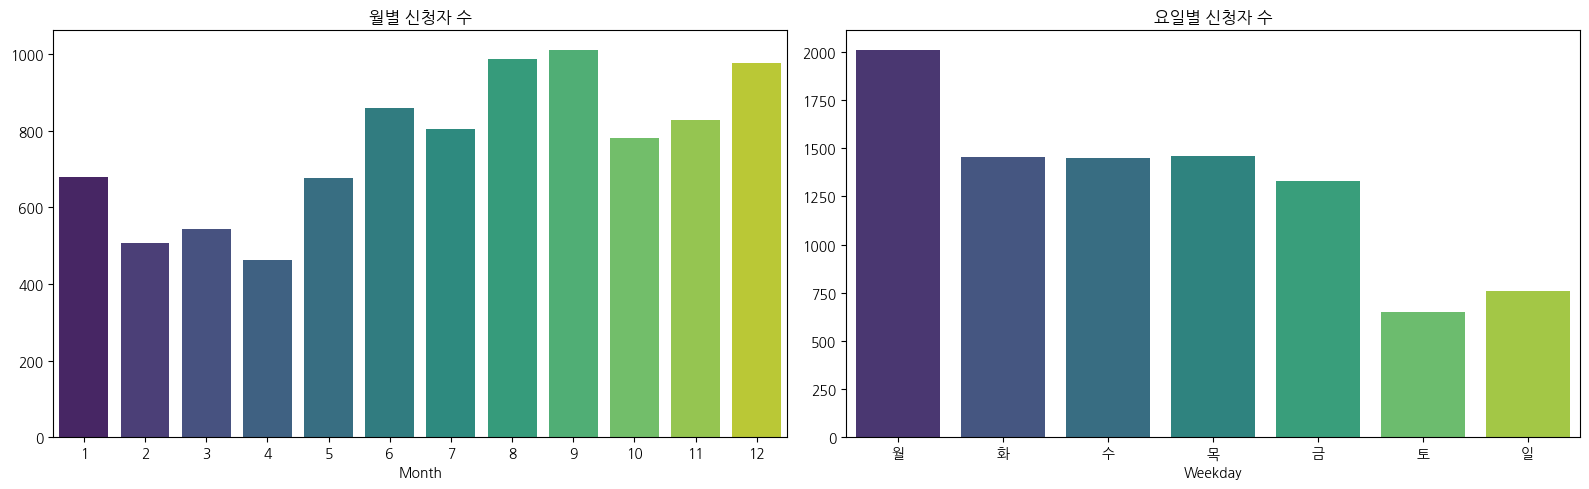

In [ ]:
register_df['trial_date_year'] = register_df['trial_date'].dt.year
register_df['trial_date_month'] = register_df['trial_date'].dt.month
register_df['trial_quarter'] = register_df['trial_date'].dt.to_period('Q')

weekday_map = {0: '월', 1: '화', 2: '수', 3: '목', 4: '금', 5: '토', 6: '일'}
register_df['trial_weekday'] = register_df['trial_date'].dt.weekday.map(weekday_map)
weekday_order = ['월', '화', '수', '목', '금', '토', '일']

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

by_month = register_df.groupby('trial_date_month')['user_uuid'].nunique()
sns.barplot(x=by_month.index, y=by_month.values, palette='viridis', ax=axes[0])
axes[0].set_title('월별 신청자 수')
axes[0].set_xlabel('Month')

by_weekday = (register_df.groupby('trial_weekday')['user_uuid'].nunique()
              .reindex(weekday_order))
sns.barplot(x=by_weekday.index, y=by_weekday.values, palette='viridis', ax=axes[1])
axes[1].set_title('요일별 신청자 수')
axes[1].set_xlabel('Weekday')

plt.tight_layout()
plt.show()

### 연도별 신청자

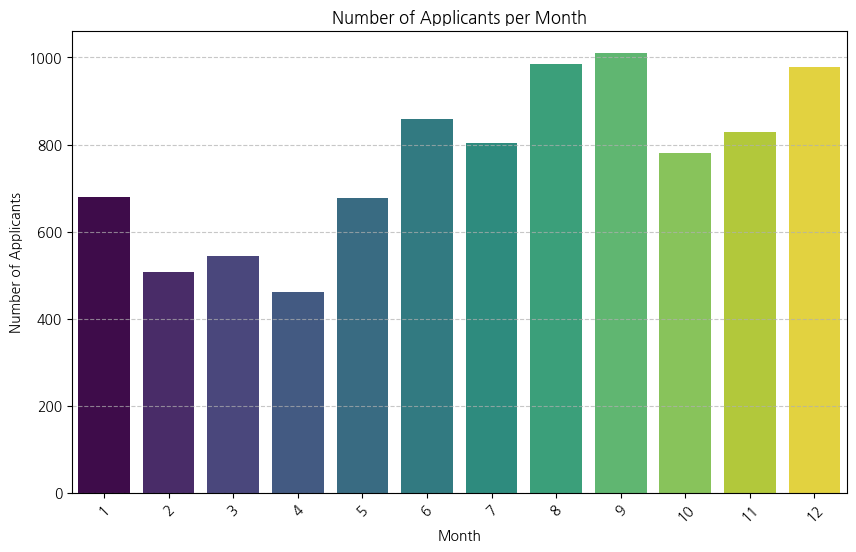

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

applicants_by_month = register_df.groupby('trial_date_month')['user_uuid'].nunique().reset_index()
applicants_by_month.columns = ['Month', 'Number of Applicants']

plt.figure(figsize=(10, 6))
sns.barplot(x='Month', y='Number of Applicants', data=applicants_by_month, palette='viridis', hue='Month', legend=False)
plt.title('Number of Applicants per Month')
plt.xlabel('Month')
plt.ylabel('Number of Applicants')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### 연-월별 신청자

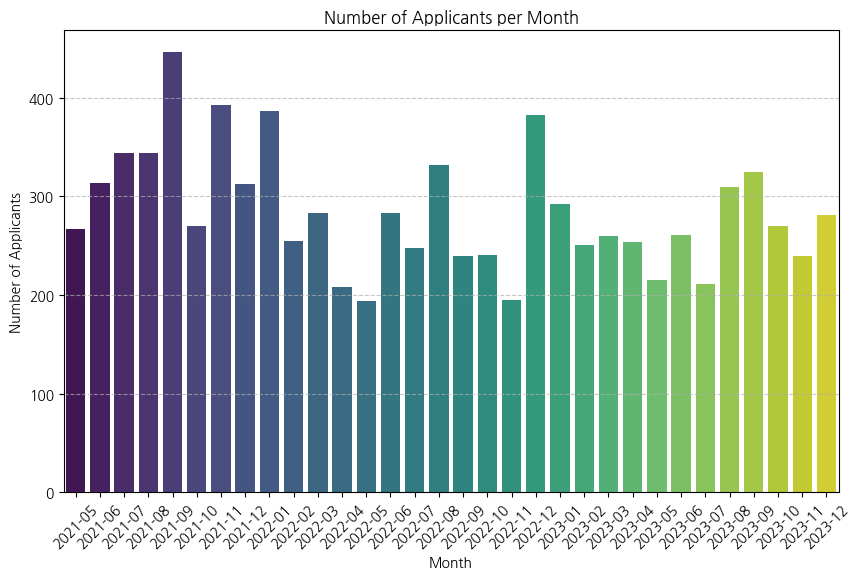

In [ ]:
register_df['trial_date_y_m'] = register_df['trial_date'].dt.strftime('%Y-%m')

applicants_by_month = register_df.groupby('trial_date_y_m')['user_uuid'].nunique().reset_index()
applicants_by_month.columns = ['Month', 'Number of Applicants']

plt.figure(figsize=(10, 6))
sns.barplot(x='Month', y='Number of Applicants', data=applicants_by_month, palette='viridis', hue='Month', legend=False)
plt.title('Number of Applicants per Month')
plt.xlabel('Month')
plt.ylabel('Number of Applicants')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### 분기별 신청자

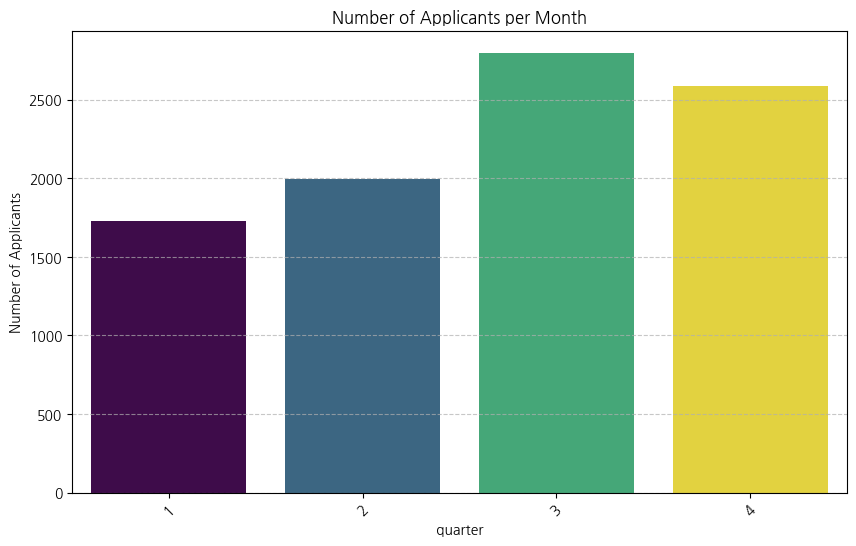

In [ ]:
register_df['trial_date_quarter'] = register_df['trial_date'].dt.quarter

applicants_by_month = register_df.groupby('trial_date_quarter')['user_uuid'].nunique().reset_index()
applicants_by_month.columns = ['Month', 'Number of Applicants']

plt.figure(figsize=(10, 6))
sns.barplot(x='Month', y='Number of Applicants', data=applicants_by_month, palette='viridis', hue='Month', legend=False)
plt.title('Number of Applicants per Month')
plt.xlabel('quarter')
plt.ylabel('Number of Applicants')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### 연-분기별 신청자

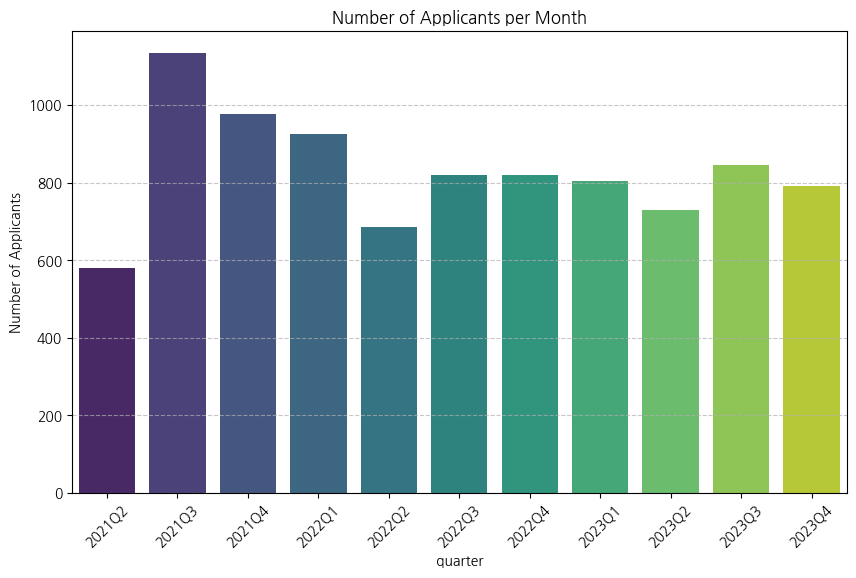

In [ ]:
register_df['trial_quarter'] = register_df['trial_date'].dt.to_period('Q')

applicants_by_month = register_df.groupby('trial_quarter')['user_uuid'].nunique().reset_index()
applicants_by_month.columns = ['Month', 'Number of Applicants']

plt.figure(figsize=(10, 6))
sns.barplot(x='Month', y='Number of Applicants', data=applicants_by_month, palette='viridis', hue='Month', legend=False)
plt.title('Number of Applicants per Month')
plt.xlabel('quarter')
plt.ylabel('Number of Applicants')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

## 4-3 분포별 시각화

### stay_time 분포

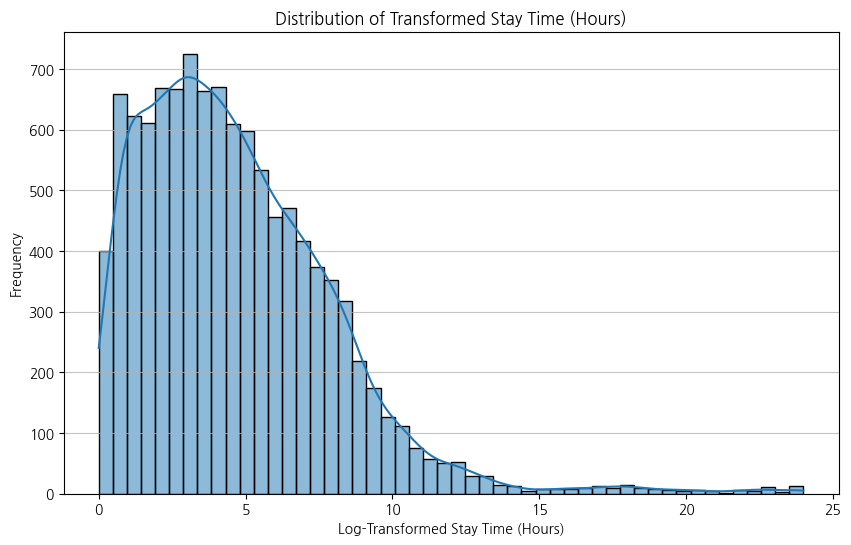

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

visit_info_df['stay_time_hours'] = visit_info_df['stay_time_second'] / 3600

plt.figure(figsize=(10, 6))
sns.histplot(visit_info_df['stay_time_hours'], bins=50, kde=True)
plt.title('Distribution of Transformed Stay Time (Hours)')
plt.xlabel('Log-Transformed Stay Time (Hours)')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.75)
plt.show()

### 사용자별 총 체류시간 분포

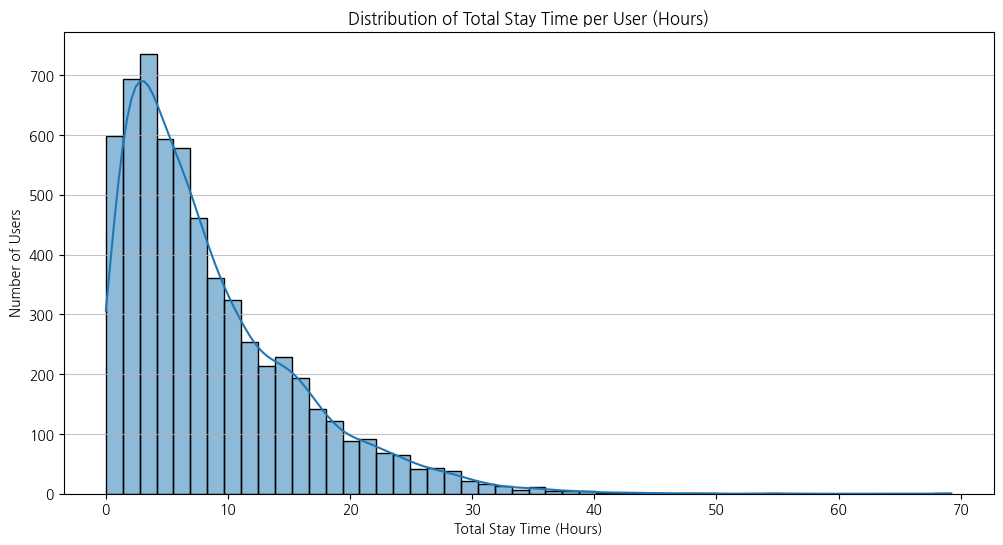

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. 사용자별 총 체류 시간(시간 단위) 집계
stay_time_per_user = visit_info_df.groupby('user_uuid')['stay_time_hours'].sum().reset_index()

# 2. 시각화 (로그 변환 없이 수행)
plt.figure(figsize=(12, 6))
sns.histplot(stay_time_per_user['stay_time_hours'], bins=50, kde=True)
plt.title('Distribution of Total Stay Time per User (Hours)')
plt.xlabel('Total Stay Time (Hours)')
plt.ylabel('Number of Users')
plt.grid(axis='y', alpha=0.75)
plt.show()

### 일차별 방문 회차 분포

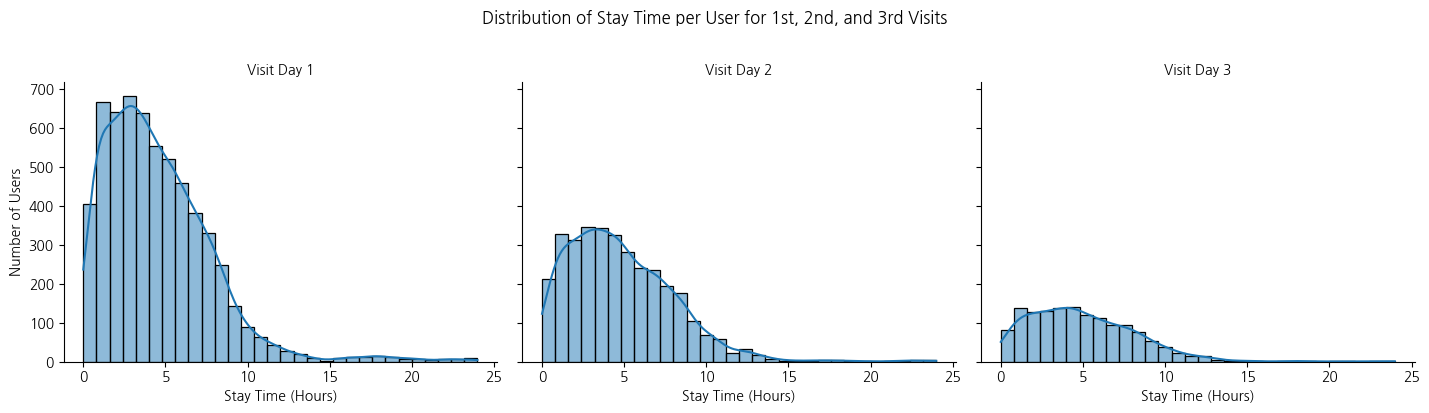

In [ ]:
# 1. 방문 회차(visit_day_number) 계산 및 1~3회차 필터링
visit_info_df_sorted = visit_info_df.sort_values(['user_uuid', 'date'])
visit_info_df_sorted['visit_day_number'] = visit_info_df_sorted.groupby('user_uuid').cumcount() + 1
first_three_visits = visit_info_df_sorted[visit_info_df_sorted['visit_day_number'] <= 3]

# 2. 시각화 (로그 변환 없이 수행)
g = sns.FacetGrid(first_three_visits, col='visit_day_number', col_wrap=3, height=4, aspect=1.2)
g.map(sns.histplot, 'stay_time_hours', bins=30, kde=True)
g.set_axis_labels('Stay Time (Hours)', 'Number of Users')
g.set_titles('Visit Day {col_name}')
plt.suptitle('Distribution of Stay Time per User for 1st, 2nd, and 3rd Visits', y=1.02)
plt.tight_layout()
plt.show()

### 신청 후 첫 방문까지 걸린 시간

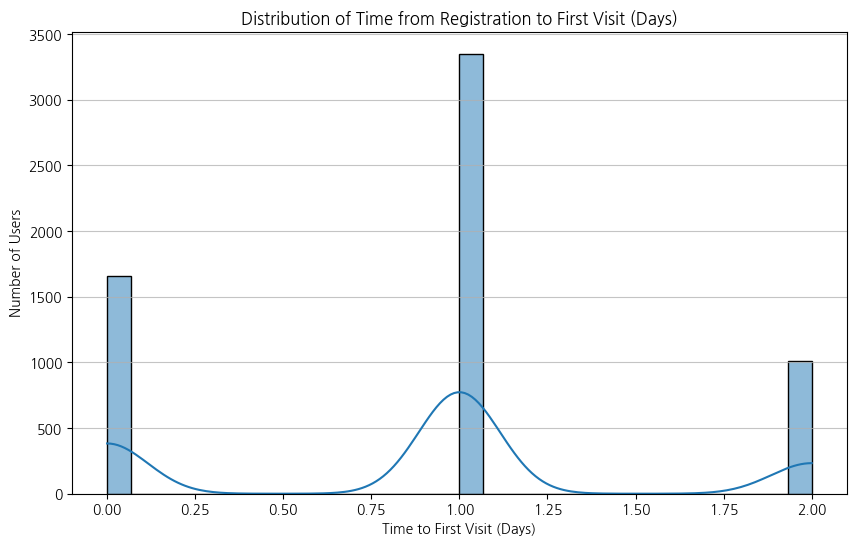

In [ ]:
# visit_info_df_sorted에서 각 user_uuid의 첫 방문 기록(visit_day_number == 1)만 필터링합니다.
first_visit_df = visit_info_df_sorted[visit_info_df_sorted['visit_day_number'] == 1].copy()

# register_df와 first_visit_df를 user_uuid 기준으로 병합
merged_df = pd.merge(register_df, first_visit_df, on='user_uuid', how='inner')

# first_enter_time의 timezone 제거 (trial_date와 연산하기 위함)
merged_df['first_enter_time_naive'] = merged_df['first_enter_time'].dt.tz_localize(None)

# 신청일로부터 첫 방문까지 걸린 시간 계산 (일 단위)
merged_df['time_to_first_visit_days'] = (merged_df['first_enter_time_naive'].dt.normalize() - merged_df['trial_date']).dt.days

# 음수 값이 있다면 (첫 방문일이 신청일보다 빠른 경우) 0으로 처리
merged_df['time_to_first_visit_days'] = merged_df['time_to_first_visit_days'].clip(lower=0)

# 시각화
plt.figure(figsize=(10, 6))
sns.histplot(merged_df['time_to_first_visit_days'], bins=30, kde=True)
plt.title('Distribution of Time from Registration to First Visit (Days)')
plt.xlabel('Time to First Visit (Days)')
plt.ylabel('Number of Users')
plt.grid(axis='y', alpha=0.75)
plt.show()

## 4-4. 결제 vs 미결제 — 방문/체류/출입 비교

In [ ]:
user_visit = (visit_info_df.groupby('user_uuid', as_index=False)
    .agg(visit_days=('date', 'count'),
         total_stay=('stay_time_second', 'sum'),
         avg_stay=('stay_time_second', 'mean')))

eda_df = payment_log_df.merge(user_visit, on='user_uuid', how='left').fillna(0)

eda_summary = (eda_df.groupby('is_payment')[['visit_days', 'total_stay', 'avg_stay']]
    .agg(['count', 'mean', 'median']).round(2).T)
eda_summary.columns = ['미결제', '결제']
eda_summary

미결제        결제
visit_days count    5685.00   3425.00
           mean        1.11      1.35
           median      1.00      1.00
total_stay count    5685.00   3425.00
           mean    19934.56  20719.41
           median  10442.00  11776.00
avg_stay   count    5685.00   3425.00
           mean    10973.82  10073.16
           median   8527.00   7956.33

## 4-5. 출입횟수 평균

In [ ]:
access_count = (
    access_log_df
    .groupby('user_uuid')
    .size()
    .reset_index(name='access_count')
)

access_count = payment_log_df.merge(
    access_count,
    on='user_uuid',
    how='left'
)

access_count['access_count'] = access_count['access_count'].fillna(0)

access_count.groupby('is_payment')['access_count'].agg(['count','mean'])

,count,mean
is_payment,,
0,5685,6.833245
1,3425,7.145401


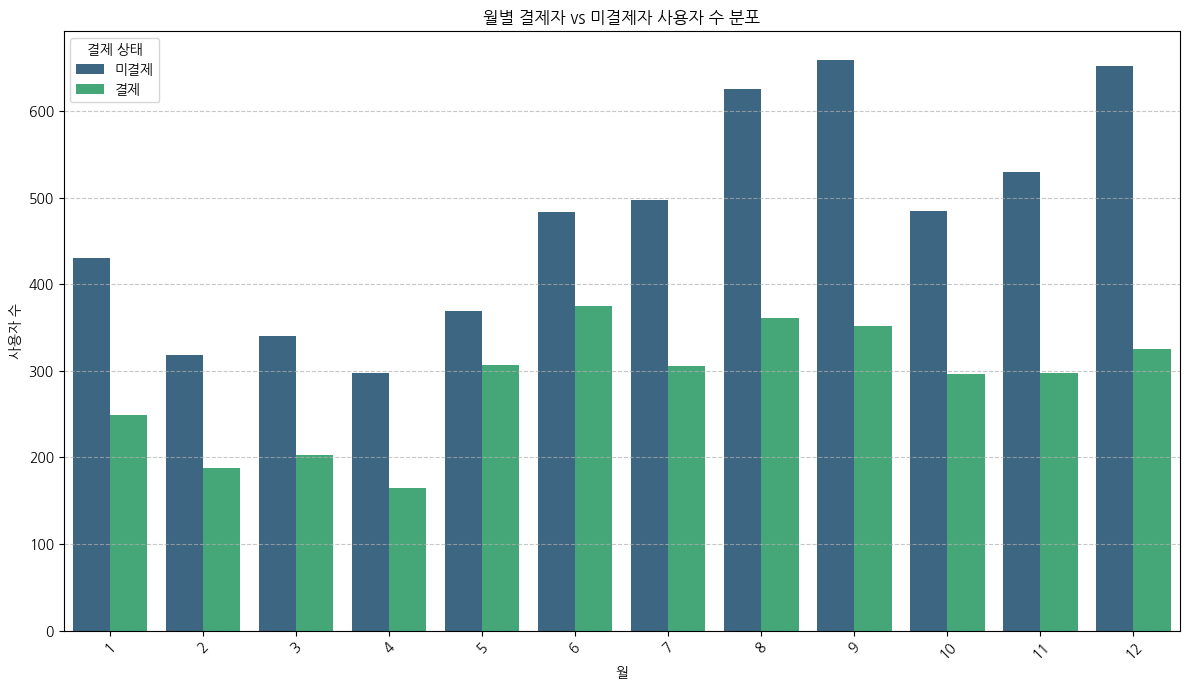

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# payment_log_df와 register_df 병합
payment_register_merged = pd.merge(register_df, payment_log_df[['user_uuid', 'is_payment']], on='user_uuid', how='left')

# 월별 결제자/미결제자 수 집계
monthly_payment_counts = payment_register_merged.groupby(['trial_date_month', 'is_payment'])['user_uuid'].nunique().reset_index()
monthly_payment_counts.columns = ['Month', 'Payment Status', 'Number of Users']

# Payment Status를 '미결제'와 '결제'로 변경
monthly_payment_counts['Payment Status'] = monthly_payment_counts['Payment Status'].map({0: '미결제', 1: '결제'})

# 시각화
plt.figure(figsize=(12, 7))
sns.barplot(x='Month', y='Number of Users', hue='Payment Status', data=monthly_payment_counts, palette='viridis')
plt.title('월별 결제자 vs 미결제자 사용자 수 분포')
plt.xlabel('월')
plt.ylabel('사용자 수')
plt.xticks(rotation=45)
plt.legend(title='결제 상태')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## 4-6. 지점별 결제율

In [ ]:
first_site = (visit_info_df.sort_values('first_enter_time')
    .groupby('user_uuid', as_index=False).first()[['user_uuid', 'site_id']])

site_payment = first_site.merge(payment_log_df[['user_uuid', 'is_payment']], on='user_uuid', how='left')

site_payment_rate = (site_payment.groupby('site_id')
    .agg(사용자수=('user_uuid', 'count'), 결제자수=('is_payment', 'sum'), 결제율=('is_payment', 'mean')))
site_payment_rate['결제율'] = (site_payment_rate['결제율'] * 100).round(2)
site_payment_rate.sort_values('결제율', ascending=False)

,사용자수,결제자수,결제율
site_id,,,
5,552,252,45.65
3,1227,517,42.14
49,129,54,41.86
1,759,311,40.97
4,464,186,40.09
2,1014,367,36.19
6,1166,411,35.25
17,421,146,34.68
47,291,93,31.96


## 4-7. 방문 여부별 결제율

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

visit_info_df_sorted = visit_info_df.sort_values(['user_uuid', 'date']).copy()
visit_info_df_sorted['visit_day_number'] = visit_info_df_sorted.groupby('user_uuid').cumcount() + 1

register_feat = register_df[['user_uuid', 'trial_date']].copy()

first_visit = (
    visit_info_df_sorted[visit_info_df_sorted['visit_day_number'] == 1]
    [['user_uuid', 'first_enter_time']]
    .copy()
)
first_visit['첫방문일'] = pd.to_datetime(first_visit['first_enter_time']).dt.normalize()

days_to_first = register_feat[['user_uuid', 'trial_date']].merge(first_visit, on='user_uuid', how='left')
days_to_first['신청후첫방문일수'] = (
    (days_to_first['첫방문일'] - days_to_first['trial_date'])
    .dt.days.clip(lower=0)
)
days_to_first = days_to_first[['user_uuid', '신청후첫방문일수']]

payment_label = payment_log_df[['user_uuid', 'is_payment']].drop_duplicates('user_uuid')

plot_data_for_viz = payment_label.merge(days_to_first, on='user_uuid', how='left')

plot_data_for_viz['방문여부'] = np.where(plot_data_for_viz['신청후첫방문일수'].notna(), 1, 0)

visit_payment_counts = plot_data_for_viz.groupby(['방문여부', 'is_payment'])['user_uuid'].nunique().reset_index()
visit_payment_counts.columns = ['Visit Status', 'Payment Status', 'Number of Users']

visit_payment_counts['Visit Status'] = visit_payment_counts['Visit Status'].map({0: '미방문', 1: '방문'})
visit_payment_counts['Payment Status'] = visit_payment_counts['Payment Status'].map({0: '미결제', 1: '결제'})

visit_payment_counts['Percentage'] = visit_payment_counts.groupby('Visit Status')['Number of Users'].transform(lambda x: x / x.sum() * 100)

display(visit_payment_counts)

,Visit Status,Payment Status,Number of Users,Percentage
0,미방문,미결제,2003,64.801035
1,미방문,결제,1088,35.198965
2,방문,미결제,3682,61.172952
3,방문,결제,2337,38.827048


### 결제 vs 미결제 - 방문횟수별

,미결제,결제
visit_count,,
1,1860,849
2,1121,811
3,690,607


,visit_count,user_count,payment_user_count,payment_rate
0,1,2709,849,31.34
1,2,1932,811,41.98
2,3,1297,607,46.80


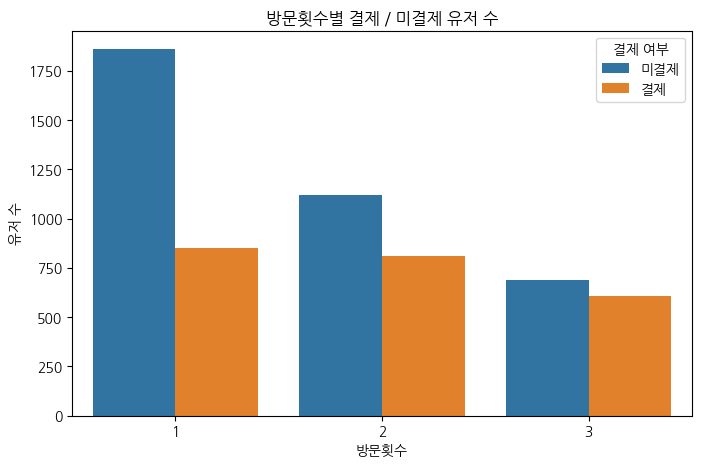

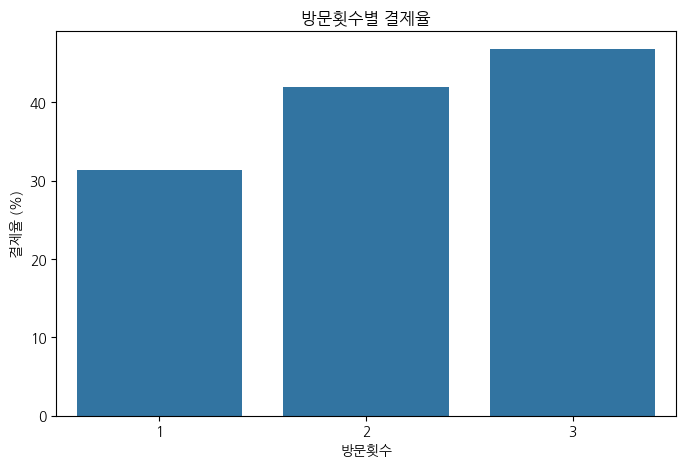

In [ ]:
# 1. 날짜 타입 변환
visit_info_df['date'] = pd.to_datetime(visit_info_df['date'])

# 2. 유저별 방문횟수 계산
visit_count_user = (
    visit_info_df
    .groupby('user_uuid')
    .agg(
        visit_count=('date', 'nunique')
    )
    .reset_index()
)

# 3. 유저별 결제 여부 계산
payment_user = (
    payment_log_df
    .groupby('user_uuid')
    .agg(
        is_payment=('is_payment', 'max')
    )
    .reset_index()
)

# 4. 방문횟수 + 결제 여부 merge
visit_payment_user = visit_count_user.merge(
    payment_user,
    on='user_uuid',
    how='left'
)

visit_payment_user['is_payment'] = visit_payment_user['is_payment'].fillna(0).astype(int)

# 5. 1회 / 2회 / 3회 방문자만 필터링
visit_123 = visit_payment_user[
    visit_payment_user['visit_count'].isin([1, 2, 3])
].copy()

# 6. 방문횟수별 결제 / 미결제 인원 수
visit_payment_pivot = pd.crosstab(
    visit_123['visit_count'],
    visit_123['is_payment']
)

visit_payment_pivot.columns = ['미결제', '결제']

display(visit_payment_pivot)

# 7. 방문횟수별 결제율
visit_payment_rate = (
    visit_123
    .groupby('visit_count')
    .agg(
        user_count=('user_uuid', 'count'),
        payment_user_count=('is_payment', 'sum'),
        payment_rate=('is_payment', 'mean')
    )
    .reset_index()
)

visit_payment_rate['payment_rate'] = visit_payment_rate['payment_rate'] * 100

display(visit_payment_rate.round(2))

# 8. 결제 / 미결제 인원 수 시각화
plt.figure(figsize=(8, 5))

sns.countplot(
    data=visit_123,
    x='visit_count',
    hue='is_payment'
)

plt.title('방문횟수별 결제 / 미결제 유저 수')
plt.xlabel('방문횟수')
plt.ylabel('유저 수')
plt.legend(title='결제 여부', labels=['미결제', '결제'])
plt.show()

# 9. 방문횟수별 결제율 시각화
plt.figure(figsize=(8, 5))

sns.barplot(
    data=visit_payment_rate,
    x='visit_count',
    y='payment_rate'
)

plt.title('방문횟수별 결제율')
plt.xlabel('방문횟수')
plt.ylabel('결제율 (%)')
plt.show()

## 4-8. 결제 vs 미결제 신청요일별

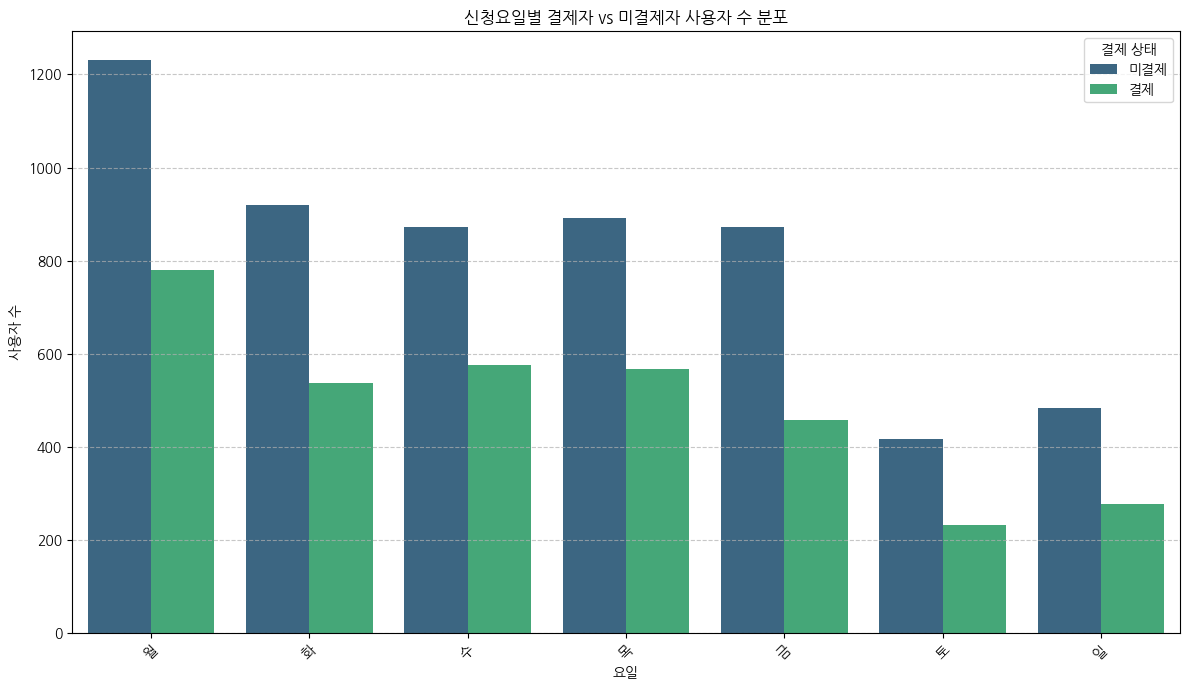

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

#payment_log_df와 register_df 병합
payment_by_weekday = pd.merge(register_df, payment_log_df[['user_uuid', 'is_payment']], on='user_uuid', how='left')

#요일별 결제자/미결제자 수 집계
weekday_payment_counts = payment_by_weekday.groupby(['trial_weekday', 'is_payment'])['user_uuid'].nunique().reset_index()
weekday_payment_counts.columns = ['Weekday', 'Payment Status', 'Number of Users']

#Payment Status를 '미결제'와 '결제'로 변경
weekday_payment_counts['Payment Status'] = weekday_payment_counts['Payment Status'].map({0: '미결제', 1: '결제'})

#요일 순서 정의 (월요일부터 일요일)
weekday_order = ['월', '화', '수', '목', '금', '토', '일']
weekday_payment_counts['Weekday'] = pd.Categorical(weekday_payment_counts['Weekday'], categories=weekday_order, ordered=True)
weekday_payment_counts = weekday_payment_counts.sort_values('Weekday')

#시각화
plt.figure(figsize=(12, 7))
sns.barplot(x='Weekday', y='Number of Users', hue='Payment Status', data=weekday_payment_counts, palette='viridis')
plt.title('신청요일별 결제자 vs 미결제자 사용자 수 분포')
plt.xlabel('요일')
plt.ylabel('사용자 수')
plt.xticks(rotation=45)
plt.legend(title='결제 상태')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## 4-9. 결제 vs 미결제 - 주말방문포함

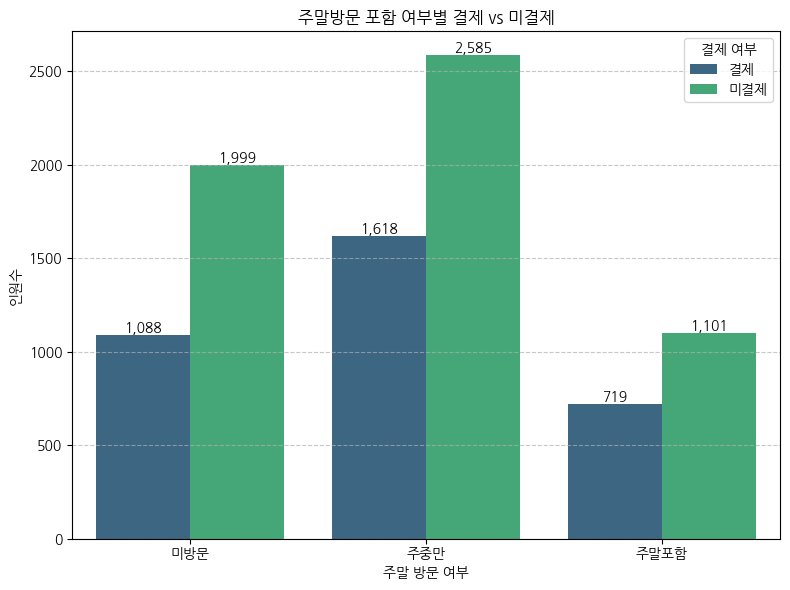


── 주말방문포함 결제율 ──


is_payment,결제(%),미결제(%)
주말방문포함_label,,
미방문,35.2,64.8
주중만,38.5,61.5
주말포함,39.5,60.5


In [ ]:
visit_info_df_sorted['요일'] = pd.to_datetime(visit_info_df_sorted['date']).dt.dayofweek

weekend_visit = (
    visit_info_df_sorted[visit_info_df_sorted['visit_day_number'] <= 3]
    .groupby('user_uuid')['요일']
    .apply(lambda x: int((x >= 5).any()))
    .reset_index(name='주말방문포함')
)

plot_df = register_df[['user_uuid']].merge(weekend_visit, on='user_uuid', how='left')
plot_df['주말방문포함'] = plot_df['주말방문포함'].fillna(-1).astype(int)
plot_df = plot_df.merge(payment_label, on='user_uuid', how='left')
plot_df['is_payment'] = plot_df['is_payment'].map({0: '미결제', 1: '결제'})
plot_df['주말방문포함_label'] = plot_df['주말방문포함'].map({-1: '미방문', 0: '주중만', 1: '주말포함'})

weekend_counts = (
    plot_df.groupby(['주말방문포함_label', 'is_payment'])['user_uuid']
    .count()
    .reset_index(name='인원수')
)

plt.figure(figsize=(8, 6))
ax = sns.barplot(x='주말방문포함_label', y='인원수', hue='is_payment',
                 data=weekend_counts, palette='viridis',
                 order=['미방문', '주중만', '주말포함'])
for p in ax.patches:
    height = int(p.get_height())
    if height > 0:
        ax.annotate(f'{height:,}', (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', fontsize=10)
ax.set_title('주말방문 포함 여부별 결제 vs 미결제')
ax.set_xlabel('주말 방문 여부')
ax.set_ylabel('인원수')
ax.legend(title='결제 여부')
ax.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

print('\n── 주말방문포함 결제율 ──')
display(
    plot_df.groupby('주말방문포함_label')['is_payment']
    .value_counts(normalize=True).mul(100).round(1)
    .unstack().rename(columns={'결제': '결제(%)', '미결제': '미결제(%)'})
    .reindex(['미방문', '주중만', '주말포함'])
)

## 4-10. 결제 vs 미결제 - 신청후첫방문

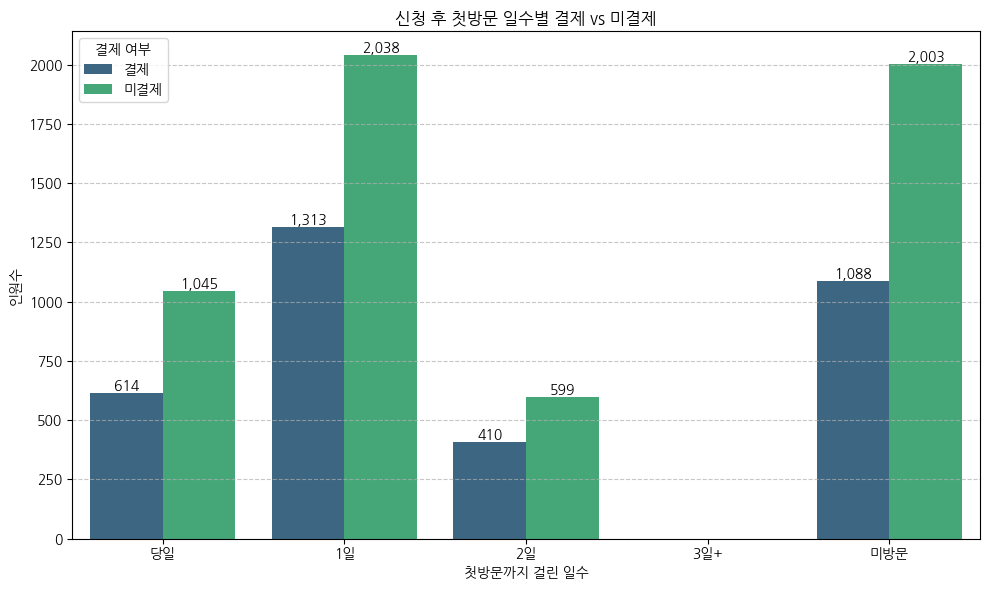


── 첫방문 일수 결제율 ──


is_payment,결제(%),미결제(%)
첫방문구간,,
당일,37.0,63.0
1일,39.2,60.8
2일,40.6,59.4
3일+,NaN,NaN
미방문,35.2,64.8


In [ ]:
first_visit = (
    visit_info_df_sorted[visit_info_df_sorted['visit_day_number'] == 1]
    [['user_uuid', 'first_enter_time']].copy()
)
first_visit['첫방문일'] = pd.to_datetime(first_visit['first_enter_time']).dt.normalize()

days_to_first = register_df[['user_uuid', 'trial_date']].merge(first_visit, on='user_uuid', how='left')
days_to_first['신청후첫방문일수'] = (
    (days_to_first['첫방문일'] - days_to_first['trial_date'])
    .dt.days.clip(lower=0)
)

plot_df = days_to_first[['user_uuid', '신청후첫방문일수']].merge(payment_label, on='user_uuid', how='left')
plot_df['is_payment'] = plot_df['is_payment'].map({0: '미결제', 1: '결제'})

def bin_days(x):
    if pd.isna(x): return '미방문'
    elif x == 0: return '당일'
    elif x == 1: return '1일'
    elif x == 2: return '2일'
    else: return '3일+'

plot_df['첫방문구간'] = plot_df['신청후첫방문일수'].apply(bin_days)
day_order = ['당일', '1일', '2일', '3일+', '미방문']

first_visit_counts = (
    plot_df.groupby(['첫방문구간', 'is_payment'])['user_uuid']
    .count()
    .reset_index(name='인원수')
)
first_visit_counts['첫방문구간'] = pd.Categorical(first_visit_counts['첫방문구간'], categories=day_order, ordered=True)
first_visit_counts = first_visit_counts.sort_values('첫방문구간')

plt.figure(figsize=(10, 6))
ax = sns.barplot(x='첫방문구간', y='인원수', hue='is_payment', data=first_visit_counts, palette='viridis')
for p in ax.patches:
    height = int(p.get_height())
    if height > 0:
        ax.annotate(f'{height:,}', (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', fontsize=10)
ax.set_title('신청 후 첫방문 일수별 결제 vs 미결제')
ax.set_xlabel('첫방문까지 걸린 일수')
ax.set_ylabel('인원수')
ax.legend(title='결제 여부')
ax.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

print('\n── 첫방문 일수 결제율 ──')
display(
    plot_df.groupby('첫방문구간')['is_payment']
    .value_counts(normalize=True).mul(100).round(1)
    .unstack().rename(columns={'결제': '결제(%)', '미결제': '미결제(%)'})
    .reindex(day_order)
)

# 5. 피처 엔지니어링

지점 면적, 출입횟수, 체류시간, 요일/주말 패턴 등을 `user_uuid` 단위로 집계해 `feature_df`를 구성함.

In [ ]:
# =========================
# 피처 엔지니어링에 필요한 중간 변수 생성
# =========================

# 방문 회차 계산
visit_info_df_sorted = visit_info_df.sort_values(['user_uuid', 'date']).copy()
visit_info_df_sorted['visit_day_number'] = (
    visit_info_df_sorted
    .groupby('user_uuid')
    .cumcount() + 1
)

# 첫 방문일 계산
first_visit = (
    visit_info_df_sorted[visit_info_df_sorted['visit_day_number'] == 1]
    [['user_uuid', 'first_enter_time']]
    .copy()
)

first_visit['첫방문일'] = pd.to_datetime(
    first_visit['first_enter_time']
).dt.normalize()

# 신청 후 첫 방문까지 걸린 일수
days_to_first = register_df[['user_uuid', 'trial_date']].merge(
    first_visit,
    on='user_uuid',
    how='left'
)

days_to_first['신청후첫방문일수'] = (
    days_to_first['첫방문일'] - days_to_first['trial_date']
).dt.days.clip(lower=0)

days_to_first = days_to_first[['user_uuid', '신청후첫방문일수']]

# 결제 라벨
payment_label = (
    payment_log_df[['user_uuid', 'is_payment']]
    .drop_duplicates('user_uuid')
)

In [ ]:
visit_info_df['stay_time_hours'] = visit_info_df['stay_time_second'] / 3600

# 방문일수
visit_days = visit_info_df.groupby('user_uuid')['date'].nunique().reset_index(name='방문일수')

# 체류시간
stay = (visit_info_df.groupby('user_uuid')['stay_time_hours']
    .agg(일평균체류시간='mean', 총체류시간='sum').round(2).reset_index())

# 출입횟수
access_total = access_log_df.groupby('user_uuid').size().reset_index(name='총출입횟수')

# 신청요일
register_feat = register_df[['user_uuid', 'trial_date']].copy()
register_feat['신청요일'] = register_feat['trial_date'].dt.dayofweek

# 주말방문포함
visit_info_df_sorted['요일'] = pd.to_datetime(visit_info_df_sorted['date']).dt.dayofweek
weekend_visit = (visit_info_df_sorted[visit_info_df_sorted['visit_day_number'] <= 3]
    .groupby('user_uuid')['요일'].apply(lambda x: int((x >= 5).any()))
    .reset_index(name='주말방문포함'))

# 신청후첫방문일수 (위에서 계산한 days_to_first 재사용)
days_to_first_feat = days_to_first[['user_uuid', '신청후첫방문일수']]

# ── 병합 ──
feature_df = register_feat[['user_uuid', '신청요일']]
for df in [visit_days, stay, access_total, weekend_visit, days_to_first_feat]:
    feature_df = feature_df.merge(df, on='user_uuid', how='left')

feature_df['방문여부'] = np.where(feature_df['신청후첫방문일수'].notna(), 1, 0)
feature_df = feature_df.fillna(-1)

# is_payment 라벨 병합
feature_df = feature_df.merge(payment_label, on='user_uuid', how='left')

# 결제 정보가 없는 유저는 미결제로 처리
feature_df['is_payment'] = feature_df['is_payment'].fillna(0).astype(int)

print(feature_df.shape)
feature_df.head()

(9110, 10)


,user_uuid,신청요일,방문일수,일평균체류시간,총체류시간,총출입횟수,주말방문포함,신청후첫방문일수,방문여부,is_payment
0,badbde4d-886b-4992-a8e3-fd0c05640183,5,-1.0,-1.00,-1.00,-1.0,-1.0,-1.0,0,1
1,e079e682-62f2-4c05-84b9-86913e3dc146,5,1.0,2.75,2.75,6.0,1.0,1.0,1,0
2,f25078d1-1030-485c-85c5-dc82d6987043,5,-1.0,-1.00,-1.00,-1.0,-1.0,-1.0,0,1
3,844319ff-cd15-4633-9900-6eaf4dc68b68,5,-1.0,-1.00,-1.00,-1.0,-1.0,-1.0,0,1
4,9f5e2bd3-65c9-4800-84c1-f5c93f44d096,5,-1.0,-1.00,-1.00,-1.0,-1.0,-1.0,0,1


## 5-1. 파생 피처 추가

In [ ]:
# 방문당체류시간
# 방문일수가 1 이상인 경우에만 계산
# 미방문자는 -1로 처리

feature_df['방문당체류시간'] = np.where(
    feature_df['방문일수'] > 0,
    feature_df['총체류시간'] / feature_df['방문일수'],
    -1
)

feature_df['방문당체류시간'] = (
    feature_df['방문당체류시간']
    .replace([np.inf, -np.inf], -1)
    .fillna(-1)
)

print(feature_df.shape)
feature_df.head()

(9110, 11)


,user_uuid,신청요일,방문일수,일평균체류시간,총체류시간,총출입횟수,주말방문포함,신청후첫방문일수,방문여부,is_payment,방문당체류시간
0,badbde4d-886b-4992-a8e3-fd0c05640183,5,-1.0,-1.00,-1.00,-1.0,-1.0,-1.0,0,1,-1.00
1,e079e682-62f2-4c05-84b9-86913e3dc146,5,1.0,2.75,2.75,6.0,1.0,1.0,1,0,2.75
2,f25078d1-1030-485c-85c5-dc82d6987043,5,-1.0,-1.00,-1.00,-1.0,-1.0,-1.0,0,1,-1.00
3,844319ff-cd15-4633-9900-6eaf4dc68b68,5,-1.0,-1.00,-1.00,-1.0,-1.0,-1.0,0,1,-1.00
4,9f5e2bd3-65c9-4800-84c1-f5c93f44d096,5,-1.0,-1.00,-1.00,-1.0,-1.0,-1.0,0,1,-1.00


## 5-2. 피처-타겟 상관관계

/tmp/ipykernel_2352/3233015672.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=corr_with_target.values, y=corr_with_target.index, palette='viridis')


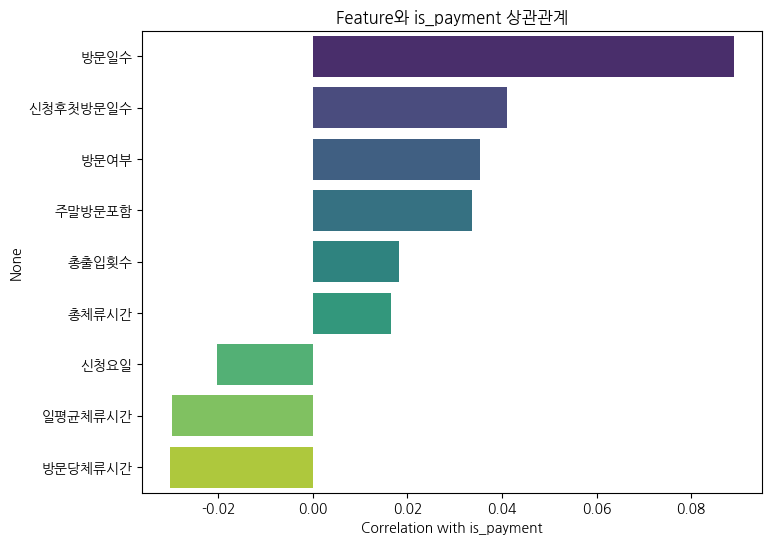

,is_payment
방문일수,0.089081
신청후첫방문일수,0.040975
방문여부,0.035464
주말방문포함,0.033757
총출입횟수,0.018163
총체류시간,0.016537
신청요일,-0.020336
일평균체류시간,-0.029841
방문당체류시간,-0.030077


In [ ]:
feature_candidates = [
    '신청요일',	'방문일수',	'일평균체류시간','총체류시간', '총출입횟수', '주말방문포함', '신청후첫방문일수', '방문여부', '방문당체류시간'
]

corr_with_target = (feature_df[feature_candidates + ['is_payment']]
    .corr(numeric_only=True)['is_payment'].drop('is_payment').sort_values(ascending=False))

plt.figure(figsize=(8, 6))
sns.barplot(x=corr_with_target.values, y=corr_with_target.index, palette='viridis')
plt.title('Feature와 is_payment 상관관계')
plt.xlabel('Correlation with is_payment')
plt.show()

corr_with_target

## 5-3. 다중공선성(VIF) 확인 — 참고용, XGBoost는 영향 적음

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_vif = feature_df[feature_candidates]
vif = pd.DataFrame({
    'Feature': X_vif.columns,
    'VIF': [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
})
vif.sort_values('VIF', ascending=False)

,Feature,VIF
8,방문당체류시간,282.015523
2,일평균체류시간,279.208928
1,방문일수,18.972230
3,총체류시간,17.043825
7,방문여부,16.155846
4,총출입횟수,3.867086
6,신청후첫방문일수,3.782514
5,주말방문포함,3.366994
0,신청요일,2.620285


# 6. Train / Valid / Test 분할

- **Train (60%)**: 모델 학습
- **Valid (20%)**: 모델 비교, threshold 튜닝
- **Test (20%)**: 최종 평가, 단 한 번만 사용

> 변수명에 `_main`을 붙여 이후 모든 셀에서 일관되게 참조함.

In [ ]:
from sklearn.model_selection import train_test_split

feature_candidates = [
    '신청요일',
    '방문일수',
    '일평균체류시간',
    '총체류시간',
    '총출입횟수',
    '주말방문포함',
    '신청후첫방문일수',
    '방문여부',
    '방문당체류시간'
]

target_col = 'is_payment'

X = feature_df[feature_candidates]
y = feature_df[target_col]

# 1차 분리: train_valid 80%, test 20%
X_train_valid, X_test, y_train_valid, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=0,
    stratify=y
)

# 2차 분리: train 60%, valid 20%
X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_valid, y_train_valid,
    test_size=0.25,
    random_state=0,
    stratify=y_train_valid
)

print('Train:', X_train.shape)
print('Valid:', X_valid.shape)
print('Test:', X_test.shape)

print('Train 결제율:', round(y_train.mean(), 3))
print('Valid 결제율:', round(y_valid.mean(), 3))
print('Test 결제율:', round(y_test.mean(), 3))

Train: (5466, 9)
Valid: (1822, 9)
Test: (1822, 9)
Train 결제율: 0.376
Valid 결제율: 0.376
Test 결제율: 0.376


# 7. 모델 학습 및 ablation test


## 7-1. XGBoost 모델 함수 만들기

In [ ]:
from xgboost import XGBClassifier

def make_xgb_model(y_train):
    neg_count = (y_train == 0).sum()
    pos_count = (y_train == 1).sum()
    scale_pos_weight = neg_count / pos_count

    model = XGBClassifier(
        n_estimators=100,
        max_depth=3,
        learning_rate=0.02,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight,
        random_state=0,
        eval_metric='logloss'
    )

    return model

## 7-2 threshold 비교함수 만들기


In [ ]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

def evaluate_thresholds(model, X_valid, y_valid, thresholds=np.arange(0.1, 0.91, 0.05)):
    y_valid_proba = model.predict_proba(X_valid)[:, 1]

    result_list = []

    for threshold in thresholds:
        y_valid_pred = (y_valid_proba >= threshold).astype(int)

        result_list.append({
            'threshold': round(threshold, 2),
            'accuracy': accuracy_score(y_valid, y_valid_pred),
            'precision': precision_score(y_valid, y_valid_pred, zero_division=0),
            'recall': recall_score(y_valid, y_valid_pred, zero_division=0),
            'f1': f1_score(y_valid, y_valid_pred, zero_division=0),
            'roc_auc': roc_auc_score(y_valid, y_valid_proba)
        })

    return pd.DataFrame(result_list)

## 7-3 전체 피처 기준 XGBoost 확인

In [ ]:
xgb_model = make_xgb_model(y_train)

xgb_model.fit(X_train, y_train)

threshold_result_df = evaluate_thresholds(
    xgb_model,
    X_valid,
    y_valid
)

display(
    threshold_result_df
    .sort_values('f1', ascending=False)
    .head(10)
)

,threshold,accuracy,precision,recall,f1,roc_auc
6,0.40,0.413831,0.387419,0.962044,0.552389,0.575292
5,0.35,0.377058,0.376238,0.998540,0.546544,0.575292
0,0.10,0.375960,0.375960,1.000000,0.546470,0.575292
1,0.15,0.375960,0.375960,1.000000,0.546470,0.575292
2,0.20,0.375960,0.375960,1.000000,0.546470,0.575292
4,0.30,0.375960,0.375960,1.000000,0.546470,0.575292
3,0.25,0.375960,0.375960,1.000000,0.546470,0.575292
7,0.45,0.435236,0.389602,0.886131,0.541239,0.575292
8,0.50,0.601537,0.462247,0.366423,0.408795,0.575292
9,0.55,0.634468,0.529052,0.252555,0.341897,0.575292


## 7-4 ablation test

### ablation test 1

In [ ]:
ablation_results = []

# 전체 피처 기준
feature_sets_for_ablation = {
    '전체 피처': feature_candidates
}

# 피처 하나씩 제거
for remove_feature in feature_candidates:
    remaining_features = [
        feature for feature in feature_candidates
        if feature != remove_feature
    ]

    feature_sets_for_ablation[f'{remove_feature} 제거'] = remaining_features


for feature_set_name, feature_cols in feature_sets_for_ablation.items():
    X_train_fs = X_train[feature_cols]
    X_valid_fs = X_valid[feature_cols]

    model = make_xgb_model(y_train)
    model.fit(X_train_fs, y_train)

    threshold_df = evaluate_thresholds(
        model,
        X_valid_fs,
        y_valid
    )

    # 각 피처 조합에서 F1이 가장 좋은 threshold만 저장
    best_row = threshold_df.sort_values('f1', ascending=False).iloc[0]

    ablation_results.append({
        'feature_set': feature_set_name,
        'removed_feature': feature_set_name.replace(' 제거', '') if feature_set_name != '전체 피처' else '없음',
        'n_features': len(feature_cols),
        'features': feature_cols,
        'best_threshold': best_row['threshold'],
        'accuracy': best_row['accuracy'],
        'precision': best_row['precision'],
        'recall': best_row['recall'],
        'f1': best_row['f1'],
        'roc_auc': best_row['roc_auc']
    })

ablation_result_df = pd.DataFrame(ablation_results)

display(
    ablation_result_df
    .sort_values('f1', ascending=False)
)

,feature_set,removed_feature,n_features,features,best_threshold,accuracy,precision,recall,f1,roc_auc
3,일평균체류시간 제거,일평균체류시간,8,"[신청요일, 방문일수, 총체류시간, 총출입횟수, 주말방문포함, 신청후첫방문일수, 방...",0.4,0.412184,0.387660,0.972263,0.554307,0.577979
1,신청요일 제거,신청요일,8,"[방문일수, 일평균체류시간, 총체류시간, 총출입횟수, 주말방문포함, 신청후첫방문일수...",0.4,0.415477,0.388367,0.964964,0.553833,0.570393
6,주말방문포함 제거,주말방문포함,8,"[신청요일, 방문일수, 일평균체류시간, 총체류시간, 총출입횟수, 신청후첫방문일수, ...",0.4,0.415477,0.388235,0.963504,0.553459,0.576357
4,총체류시간 제거,총체류시간,8,"[신청요일, 방문일수, 일평균체류시간, 총출입횟수, 주말방문포함, 신청후첫방문일수,...",0.4,0.412733,0.387493,0.967883,0.553422,0.576251
9,방문당체류시간 제거,방문당체류시간,8,"[신청요일, 방문일수, 일평균체류시간, 총체류시간, 총출입횟수, 주말방문포함, 신청...",0.4,0.413831,0.387683,0.964964,0.553138,0.576891
8,방문여부 제거,방문여부,8,"[신청요일, 방문일수, 일평균체류시간, 총체류시간, 총출입횟수, 주말방문포함, 신청...",0.4,0.414929,0.387875,0.962044,0.552852,0.576778
0,전체 피처,없음,9,"[신청요일, 방문일수, 일평균체류시간, 총체류시간, 총출입횟수, 주말방문포함, 신청...",0.4,0.413831,0.387419,0.962044,0.552389,0.575292
5,총출입횟수 제거,총출입횟수,8,"[신청요일, 방문일수, 일평균체류시간, 총체류시간, 주말방문포함, 신청후첫방문일수,...",0.4,0.415477,0.387574,0.956204,0.551579,0.578799
7,신청후첫방문일수 제거,신청후첫방문일수,8,"[신청요일, 방문일수, 일평균체류시간, 총체류시간, 총출입횟수, 주말방문포함, 방문...",0.4,0.412733,0.386831,0.960584,0.551551,0.572088
2,방문일수 제거,방문일수,8,"[신청요일, 일평균체류시간, 총체류시간, 총출입횟수, 주말방문포함, 신청후첫방문일수...",0.4,0.398463,0.382638,0.978102,0.550082,0.574318


### ablation test 2

In [ ]:
feature_candidates_2 = [
    '신청요일',
    '방문일수',
    '일평균체류시간',
    '총체류시간',
    '총출입횟수',
    '주말방문포함',
    '신청후첫방문일수',
    '방문여부'
]


In [ ]:
ablation_results = []

# 전체 피처 기준
feature_sets_for_ablation = {
    '전체 피처': feature_candidates_2
}

# 피처 하나씩 제거
for remove_feature in feature_candidates_2:
    remaining_features = [
        feature for feature in feature_candidates_2
        if feature != remove_feature
    ]

    feature_sets_for_ablation[f'{remove_feature} 제거'] = remaining_features


for feature_set_name, feature_cols in feature_sets_for_ablation.items():
    X_train_fs = X_train[feature_cols]
    X_valid_fs = X_valid[feature_cols]

    model = make_xgb_model(y_train)
    model.fit(X_train_fs, y_train)

    threshold_df = evaluate_thresholds(
        model,
        X_valid_fs,
        y_valid
    )

    # 각 피처 조합에서 F1이 가장 좋은 threshold만 저장
    best_row = threshold_df.sort_values('f1', ascending=False).iloc[0]

    ablation_results.append({
        'feature_set': feature_set_name,
        'removed_feature': feature_set_name.replace(' 제거', '') if feature_set_name != '전체 피처' else '없음',
        'n_features': len(feature_cols),
        'features': feature_cols,
        'best_threshold': best_row['threshold'],
        'accuracy': best_row['accuracy'],
        'precision': best_row['precision'],
        'recall': best_row['recall'],
        'f1': best_row['f1'],
        'roc_auc': best_row['roc_auc']
    })

ablation_result_df = pd.DataFrame(ablation_results)

display(
    ablation_result_df
    .sort_values('f1', ascending=False)
)

,feature_set,removed_feature,n_features,features,best_threshold,accuracy,precision,recall,f1,roc_auc
0,전체 피처,없음,8,"[신청요일, 방문일수, 일평균체류시간, 총체류시간, 총출입횟수, 주말방문포함, 신청...",0.4,0.413831,0.387683,0.964964,0.553138,0.576891
6,주말방문포함 제거,주말방문포함,7,"[신청요일, 방문일수, 일평균체류시간, 총체류시간, 총출입횟수, 신청후첫방문일수, ...",0.4,0.407794,0.385598,0.969343,0.551724,0.578783
8,방문여부 제거,방문여부,7,"[신청요일, 방문일수, 일평균체류시간, 총체류시간, 총출입횟수, 주말방문포함, 신청...",0.4,0.406147,0.385061,0.970803,0.551410,0.578208
7,신청후첫방문일수 제거,신청후첫방문일수,7,"[신청요일, 방문일수, 일평균체류시간, 총체류시간, 총출입횟수, 주말방문포함, 방문여부]",0.4,0.404501,0.384393,0.970803,0.550725,0.573236
5,총출입횟수 제거,총출입횟수,7,"[신청요일, 방문일수, 일평균체류시간, 총체류시간, 주말방문포함, 신청후첫방문일수,...",0.4,0.403403,0.384083,0.972263,0.550641,0.581301
1,신청요일 제거,신청요일,7,"[방문일수, 일평균체류시간, 총체류시간, 총출입횟수, 주말방문포함, 신청후첫방문일수...",0.4,0.410538,0.385790,0.959124,0.550251,0.569787
4,총체류시간 제거,총체류시간,7,"[신청요일, 방문일수, 일평균체류시간, 총출입횟수, 주말방문포함, 신청후첫방문일수,...",0.4,0.396817,0.382118,0.979562,0.549775,0.581001
2,방문일수 제거,방문일수,7,"[신청요일, 일평균체류시간, 총체류시간, 총출입횟수, 주말방문포함, 신청후첫방문일수...",0.4,0.384193,0.378679,0.995620,0.548673,0.572507
3,일평균체류시간 제거,일평균체류시간,7,"[신청요일, 방문일수, 총체류시간, 총출입횟수, 주말방문포함, 신청후첫방문일수, 방...",0.1,0.375960,0.375960,1.000000,0.546470,0.579576


# 8. 전체 피처 조합 비교

In [ ]:
# 선택된 최종 피처
selected_candidate_features = [
    '신청요일',
    '방문일수',
    '일평균체류시간',
    '총체류시간',
    '주말방문포함',
    '신청후첫방문일수',
    '방문여부'
]

In [ ]:
# 피처들의 조합 확인
from itertools import combinations

all_feature_sets = {}

for r in range(1, len(selected_candidate_features) + 1):
    for combo in combinations(selected_candidate_features, r):
        feature_set_name = ' + '.join(combo)
        all_feature_sets[feature_set_name] = list(combo)

print('전체 조합 수:', len(all_feature_sets))

전체 조합 수: 127


In [ ]:
# 가장 좋은 피처 조합 검증

combo_results = []

for feature_set_name, feature_cols in all_feature_sets.items():
    X_train_fs = X_train[feature_cols]
    X_valid_fs = X_valid[feature_cols]

    model = make_xgb_model(y_train)
    model.fit(X_train_fs, y_train)

    threshold_df = evaluate_thresholds(
        model,
        X_valid_fs,
        y_valid
    )

    best_row = threshold_df.sort_values('f1', ascending=False).iloc[0]

    combo_results.append({
        'features': feature_cols,
        'n_features': len(feature_cols),
        'best_threshold': best_row['threshold'],
        'accuracy': best_row['accuracy'],
        'precision': best_row['precision'],
        'recall': best_row['recall'],
        'f1': best_row['f1'],
        'roc_auc': best_row['roc_auc']
    })

combo_result_df = pd.DataFrame(combo_results)

display(
    combo_result_df
    .sort_values('f1', ascending=False)
    .head(20)
)

,features,n_features,best_threshold,accuracy,precision,recall,f1,roc_auc
99,"[신청요일, 방문일수, 일평균체류시간, 총체류시간, 신청후첫방문일수]",5,0.40,0.412184,0.387135,0.966423,0.552818,0.580549
92,"[방문일수, 주말방문포함, 신청후첫방문일수, 방문여부]",4,0.45,0.433589,0.392835,0.928467,0.552083,0.565430
50,"[방문일수, 주말방문포함, 신청후첫방문일수]",3,0.45,0.433589,0.392835,0.928467,0.552083,0.565073
70,"[신청요일, 방문일수, 주말방문포함, 신청후첫방문일수]",4,0.45,0.437980,0.394129,0.921168,0.552056,0.569796
72,"[신청요일, 방문일수, 신청후첫방문일수, 방문여부]",4,0.45,0.437980,0.394129,0.921168,0.552056,0.569192
86,"[방문일수, 일평균체류시간, 주말방문포함, 신청후첫방문일수]",4,0.40,0.409440,0.386006,0.966423,0.551667,0.577444
83,"[방문일수, 일평균체류시간, 총체류시간, 주말방문포함]",4,0.40,0.413282,0.386926,0.959124,0.551406,0.569022
85,"[방문일수, 일평균체류시간, 총체류시간, 방문여부]",4,0.40,0.412184,0.386604,0.960584,0.551320,0.568096
43,"[방문일수, 일평균체류시간, 총체류시간]",3,0.40,0.409989,0.385831,0.962044,0.550773,0.568781
113,"[방문일수, 일평균체류시간, 총체류시간, 주말방문포함, 신청후첫방문일수]",5,0.40,0.414380,0.386982,0.954745,0.550737,0.572758


## 혹시몰라서 처음에 했던 전체 후보들로도 한번 전체 피처 조합 비교

In [ ]:
feature_candidates = [
    '신청요일',
    '방문일수',
    '일평균체류시간',
    '총체류시간',
    '총출입횟수',
    '주말방문포함',
    '신청후첫방문일수',
    '방문여부',
    '방문당체류시간'
]


In [ ]:
# 피처들의 조합 확인
from itertools import combinations

all_feature_sets_2 = {}

for r in range(1, len(feature_candidates) + 1):
    for combo in combinations(feature_candidates, r):
        feature_set_name = ' + '.join(combo)
        all_feature_sets_2[feature_set_name] = list(combo)

print('전체 조합 수:', len(all_feature_sets_2))

전체 조합 수: 511


In [ ]:
# 디게 오래걸림ㅠ

combo_results_2 = []

for feature_set_name, feature_cols in all_feature_sets_2.items():
    X_train_fs = X_train[feature_cols]
    X_valid_fs = X_valid[feature_cols]

    model = make_xgb_model(y_train)
    model.fit(X_train_fs, y_train)

    threshold_df = evaluate_thresholds(
        model,
        X_valid_fs,
        y_valid
    )

    best_row = threshold_df.sort_values('f1', ascending=False).iloc[0]

    combo_results_2.append({
        'features': feature_cols,
        'n_features': len(feature_cols),
        'best_threshold': best_row['threshold'],
        'accuracy': best_row['accuracy'],
        'precision': best_row['precision'],
        'recall': best_row['recall'],
        'f1': best_row['f1'],
        'roc_auc': best_row['roc_auc']
    })

combo_result_2_df = pd.DataFrame(combo_results_2)

display(
    combo_result_2_df
    .sort_values('f1', ascending=False)
    .head(20)
)

,features,n_features,best_threshold,accuracy,precision,recall,f1,roc_auc
85,"[방문일수, 총출입횟수, 신청후첫방문일수]",3,0.45,0.438529,0.395291,0.931387,0.555024,0.570232
185,"[방문일수, 일평균체류시간, 총체류시간, 총출입횟수]",4,0.40,0.417673,0.389151,0.963504,0.554389,0.567040
507,"[신청요일, 방문일수, 총체류시간, 총출입횟수, 주말방문포함, 신청후첫방문일수, 방...",8,0.40,0.412184,0.387660,0.972263,0.554307,0.577979
509,"[방문일수, 일평균체류시간, 총체류시간, 총출입횟수, 주말방문포함, 신청후첫방문일수...",8,0.40,0.415477,0.388367,0.964964,0.553833,0.570393
496,"[방문일수, 일평균체류시간, 총체류시간, 총출입횟수, 신청후첫방문일수, 방문여부, ...",7,0.40,0.415477,0.388367,0.964964,0.553833,0.570027
504,"[신청요일, 방문일수, 일평균체류시간, 총체류시간, 총출입횟수, 신청후첫방문일수, ...",8,0.40,0.415477,0.388235,0.963504,0.553459,0.576357
506,"[신청요일, 방문일수, 일평균체류시간, 총출입횟수, 주말방문포함, 신청후첫방문일수,...",8,0.40,0.412733,0.387493,0.967883,0.553422,0.576251
501,"[신청요일, 방문일수, 일평균체류시간, 총체류시간, 총출입횟수, 주말방문포함, 신청...",8,0.40,0.413831,0.387683,0.964964,0.553138,0.576891
255,"[신청요일, 방문일수, 일평균체류시간, 총체류시간, 총출입횟수]",5,0.40,0.413831,0.387683,0.964964,0.553138,0.571180
502,"[신청요일, 방문일수, 일평균체류시간, 총체류시간, 총출입횟수, 주말방문포함, 신청...",8,0.40,0.414929,0.387875,0.962044,0.552852,0.576778


# 9. best_features 로 다시 최종 재학습

In [ ]:
# 1. valid 기준으로 최종 조합 선택
best_combo = combo_result_2_df.sort_values('f1', ascending=False).iloc[0]

best_features = best_combo['features']
best_threshold = best_combo['best_threshold']

print('최종 피처:', best_features)
print('최종 threshold:', best_threshold)

최종 피처: ['방문일수', '총출입횟수', '신청후첫방문일수']
최종 threshold: 0.45


In [ ]:
# 2. train + valid를 합쳐서 최종 학습
X_train_valid_final = X_train_valid[best_features]
X_test_final = X_test[best_features]

final_model = make_xgb_model(y_train_valid)
final_model.fit(X_train_valid_final, y_train_valid)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.02, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=3, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=None,
              num_parallel_tree=None, ...)

# 10. Test에서 최종 평가

In [ ]:
y_test_proba = final_model.predict_proba(X_test_final)[:, 1]
y_test_pred = (y_test_proba >= best_threshold).astype(int)

최종 Test 성능 지표


,threshold,accuracy,precision,recall,f1,roc_auc
0,0.45,0.4259,0.3878,0.9109,0.544,0.5862


혼동행렬


,예측 미결제(0),예측 결제(1)
실제 미결제(0),152,985
실제 결제(1),61,624


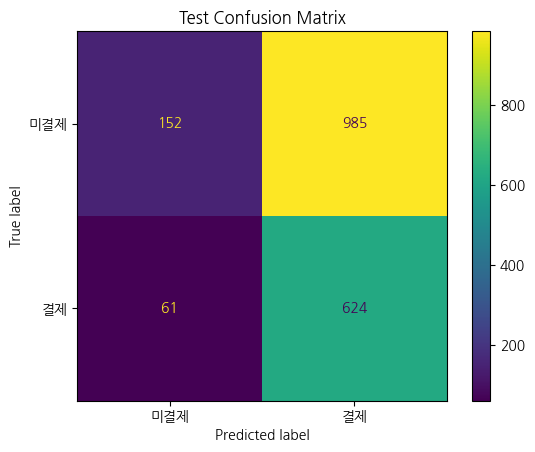

클래스별 상세 성능


,precision,recall,f1-score,support
미결제(0),0.713615,0.133685,0.225185,1137.000000
결제(1),0.387819,0.910949,0.544028,685.000000
accuracy,0.425906,0.425906,0.425906,0.425906
macro avg,0.550717,0.522317,0.384607,1822.000000
weighted avg,0.591128,0.425906,0.345057,1822.000000


In [ ]:
# =========================
# 최종 Test 성능 평가
# =========================

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# -------------------------
# 1. 주요 평가 지표
# -------------------------

test_metrics_df = pd.DataFrame([{
    'threshold': best_threshold,
    'accuracy': accuracy_score(y_test, y_test_pred),
    'precision': precision_score(y_test, y_test_pred, zero_division=0),
    'recall': recall_score(y_test, y_test_pred, zero_division=0),
    'f1': f1_score(y_test, y_test_pred, zero_division=0),
    'roc_auc': roc_auc_score(y_test, y_test_proba)
}]).round(4)

print('최종 Test 성능 지표')
display(test_metrics_df)


# -------------------------
# 2. 혼동행렬
# -------------------------

cm = confusion_matrix(y_test, y_test_pred)

cm_df = pd.DataFrame(
    cm,
    index=['실제 미결제(0)', '실제 결제(1)'],
    columns=['예측 미결제(0)', '예측 결제(1)']
)

print('혼동행렬')
display(cm_df)


# -------------------------
# 3. 혼동행렬 시각화
# -------------------------

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['미결제', '결제']
)

disp.plot(values_format='d')
plt.title('Test Confusion Matrix')
plt.show()


# -------------------------
# 4. 클래스별 상세 성능
# -------------------------

report_dict = classification_report(
    y_test,
    y_test_pred,
    target_names=['미결제(0)', '결제(1)'],
    zero_division=0,
    output_dict=True
)

report_df = pd.DataFrame(report_dict).T.round(6)

print('클래스별 상세 성능')
display(report_df)


# 11. Permutation Importance / Feature Importance

Permutation Importance는 최종 Test 평가 이후 모델 해석을 위해 확인하였고, 해당 결과를 바탕으로 피처를 다시 선택하거나 모델을 수정하지는 않았다.

XGBoost 기본 Feature Importance


,feature,xgb_importance
0,방문일수,0.624018
1,총출입횟수,0.189193
2,신청후첫방문일수,0.186790


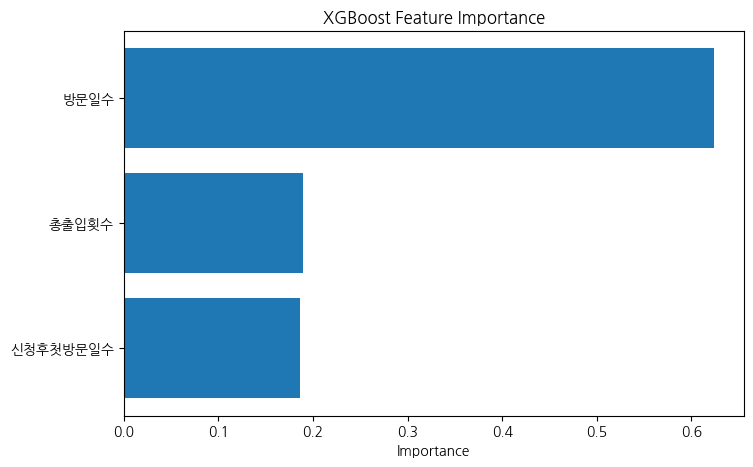

XGBoost Gain 기준 Feature Importance


,feature,gain_importance
0,방문일수,17.753948
1,총출입횟수,5.382726
2,신청후첫방문일수,5.314365


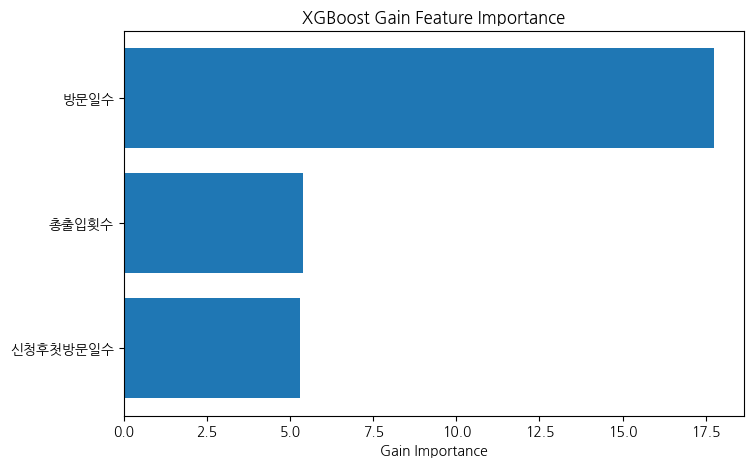

Permutation Importance


,feature,importance_mean,importance_std
0,방문일수,0.063854,0.012766
1,총출입횟수,-0.004456,0.007060
2,신청후첫방문일수,-0.009284,0.005282


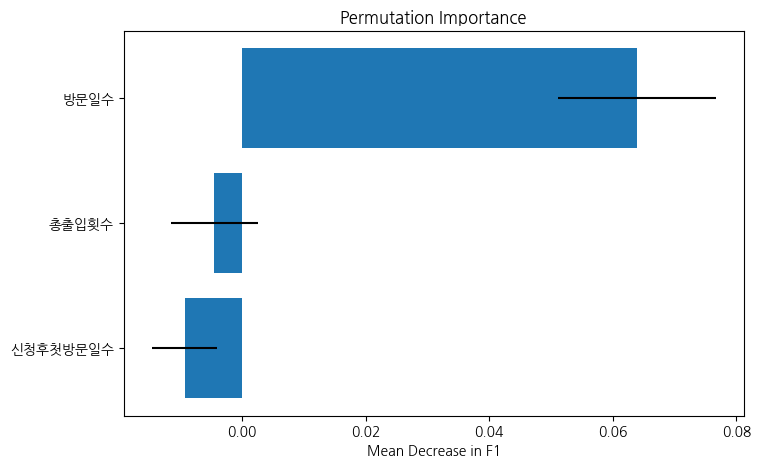

In [ ]:
# =========================
# Feature Importance / Permutation Importance 확인
# =========================

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.inspection import permutation_importance

# 한글 깨짐 방지용: 설치되어 있으면 적용, 없으면 무시
try:
    import koreanize_matplotlib
except:
    pass


# -------------------------
# 1. XGBoost 기본 Feature Importance
# -------------------------
# XGBoost 모델 내부 기준으로 계산된 중요도
# 모델이 학습 과정에서 어떤 피처를 많이 활용했는지 확인

xgb_importance_df = pd.DataFrame({
    'feature': best_features,
    'xgb_importance': final_model.feature_importances_
}).sort_values('xgb_importance', ascending=False)

print('XGBoost 기본 Feature Importance')
display(xgb_importance_df)


plt.figure(figsize=(8, 5))
plt.barh(
    xgb_importance_df['feature'],
    xgb_importance_df['xgb_importance']
)
plt.gca().invert_yaxis()
plt.xlabel('Importance')
plt.title('XGBoost Feature Importance')
plt.show()


# -------------------------
# 2. XGBoost Gain 기준 Feature Importance
# -------------------------
# gain: 해당 피처가 분기 기준으로 사용되었을 때 모델 성능 개선에 얼마나 기여했는지

booster = final_model.get_booster()

gain_score = booster.get_score(importance_type='gain')

gain_importance_df = pd.DataFrame({
    'feature': best_features,
    'gain_importance': [
        gain_score.get(feature, 0) for feature in best_features
    ]
}).sort_values('gain_importance', ascending=False)

print('XGBoost Gain 기준 Feature Importance')
display(gain_importance_df)


plt.figure(figsize=(8, 5))
plt.barh(
    gain_importance_df['feature'],
    gain_importance_df['gain_importance']
)
plt.gca().invert_yaxis()
plt.xlabel('Gain Importance')
plt.title('XGBoost Gain Feature Importance')
plt.show()


# -------------------------
# 3. Permutation Importance
# -------------------------
# 특정 피처 값을 섞었을 때 F1 점수가 얼마나 떨어지는지 확인
# 성능 하락폭이 클수록 해당 피처가 예측에 중요하다고 볼 수 있음

perm_result = permutation_importance(
    final_model,
    X_test_final,
    y_test,
    scoring='f1',
    n_repeats=20,
    random_state=0,
    n_jobs=-1
)

permutation_importance_df = pd.DataFrame({
    'feature': best_features,
    'importance_mean': perm_result.importances_mean,
    'importance_std': perm_result.importances_std
}).sort_values('importance_mean', ascending=False)

print('Permutation Importance')
display(permutation_importance_df)


plt.figure(figsize=(8, 5))
plt.barh(
    permutation_importance_df['feature'],
    permutation_importance_df['importance_mean'],
    xerr=permutation_importance_df['importance_std']
)
plt.gca().invert_yaxis()
plt.xlabel('Mean Decrease in F1')
plt.title('Permutation Importance')
plt.show()

# 왜 이 친구는 성능이 형평없는가;;;;

## FP(False Positive) 중심 오류 분석

최종 모델의 혼동행렬을 기반으로 예측 결과를 다음 네 그룹으로 구분하였다.

- TP : 실제 결제를 결제로 예측
- TN : 실제 미결제를 미결제로 예측
- FP : 실제 미결제를 결제로 예측
- FN : 실제 결제를 미결제로 예측

본 분석에서는 Precision을 낮추는 주요 원인인 FP(False Positive)를 중심으로
오분류 원인을 분석한다.

## FP 중심 오류 분석 데이터 생성

In [ ]:
# =========================
# FP 중심 오류 분석 데이터 생성
# =========================

test_result = X_test_final.copy()

test_result['actual'] = y_test.values
test_result['pred'] = y_test_pred
test_result['prob'] = y_test_proba

FP = test_result[(test_result['actual'] == 0) & (test_result['pred'] == 1)]
TN = test_result[(test_result['actual'] == 0) & (test_result['pred'] == 0)]
TP = test_result[(test_result['actual'] == 1) & (test_result['pred'] == 1)]
FN = test_result[(test_result['actual'] == 1) & (test_result['pred'] == 0)]

print('FP:', FP.shape)
print('TN:', TN.shape)
print('TP:', TP.shape)
print('FN:', FN.shape)

FP: (985, 6)
TN: (152, 6)
TP: (624, 6)
FN: (61, 6)


## 그룹별 평균 비교

FP, TN, TP, FN의 각 Feature 평균을 비교하여
오분류된 고객이 어떤 행동 특성을 가지는지 확인한다.

특히 FP와 TP의 평균이 유사하다면
현재 Feature만으로는 실제 결제 고객과 미결제 고객을
충분히 구분하지 못하고 있을 가능성을 의미한다.

In [ ]:
# =========================
# 1. 그룹별 평균 비교
# =========================

compare_mean = pd.concat([
    FP[best_features].mean().rename('FP'),
    TN[best_features].mean().rename('TN'),
    TP[best_features].mean().rename('TP'),
    FN[best_features].mean().rename('FN')
], axis=1)

display(compare_mean.round(3))

,FP,TN,TP,FN
방문일수,0.781,1.013,0.989,1.049
총출입횟수,6.804,8.487,6.298,10.164
신청후첫방문일수,0.245,0.224,0.252,0.410


## 그룹별 중앙값(Median) 비교

평균은 이상치의 영향을 받을 수 있으므로
중앙값을 함께 확인하였다.

평균과 중앙값을 함께 비교하여
각 그룹의 대표적인 행동 패턴을 확인한다.

In [ ]:
# =========================
# 2. 그룹별 중앙값 비교
# =========================

compare_median = pd.concat([
    FP[best_features].median().rename('FP'),
    TN[best_features].median().rename('TN'),
    TP[best_features].median().rename('TP'),
    FN[best_features].median().rename('FN')
], axis=1)

display(compare_median.round(3))

,FP,TN,TP,FN
방문일수,1.0,1.0,1.0,1.0
총출입횟수,4.0,6.0,4.0,7.0
신청후첫방문일수,1.0,0.0,1.0,0.0


## Feature 분포(Boxplot) 비교

평균과 중앙값만으로는 분포를 모두 설명하기 어렵다.

Boxplot을 통해

- 중앙값
- 사분위수(IQR)
- 이상치

를 함께 확인하여
FP가 TP와 얼마나 유사한 분포를 가지는지 분석한다.

In [ ]:
# =========================
# 3. 시각화용 데이터
# =========================

plot_df = pd.concat([
    FP.assign(group='FP'),
    TN.assign(group='TN'),
    TP.assign(group='TP'),
    FN.assign(group='FN')
])

plot_df['group'] = pd.Categorical(
    plot_df['group'],
    categories=['TN', 'FP', 'FN', 'TP'],
    ordered=True
)

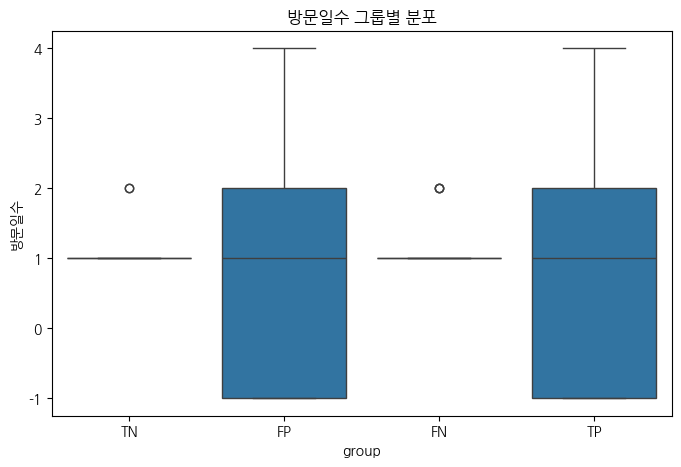

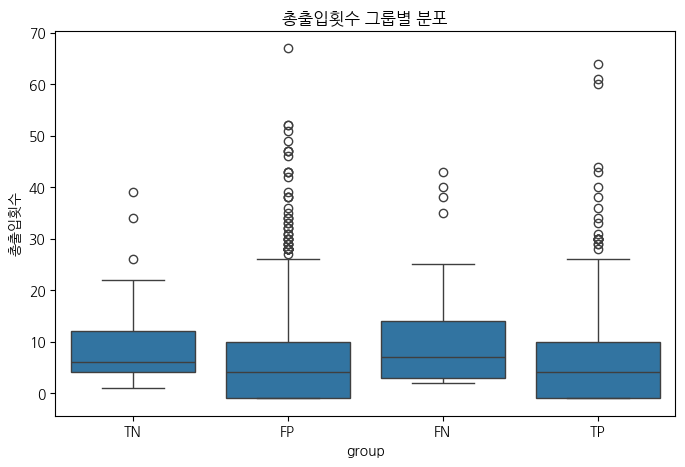

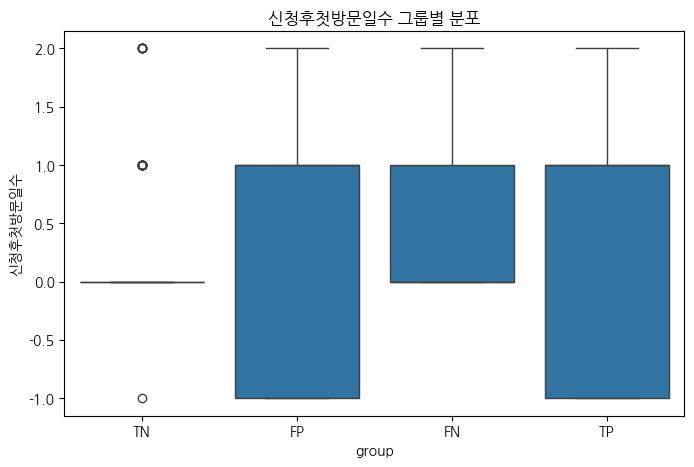

In [ ]:
# =========================
# 4. Boxplot: 최종 피처 3개 비교
# =========================

for col in best_features:
    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=plot_df,
        x='group',
        y=col
    )

    plt.title(f'{col} 그룹별 분포')
    plt.show()

## FP와 TP 직접 비교

Precision이 낮은 원인을 분석하기 위해

실제 결제 고객(TP)과
실제 미결제지만 결제로 예측된 고객(FP)의 Feature를 직접 비교하였다.

두 그룹이 매우 유사하다면
현재 Feature만으로는 두 집단을 명확히 구분하기 어렵다는 의미이다.


In [ ]:
# =========================
# 5. FP vs TP만 비교
# =========================

fp_tp_df = pd.concat([
    FP.assign(group='FP'),
    TP.assign(group='TP')
])

compare_fp_tp = pd.concat([
    FP[best_features].mean().rename('FP_mean'),
    TP[best_features].mean().rename('TP_mean'),
    FP[best_features].median().rename('FP_median'),
    TP[best_features].median().rename('TP_median')
], axis=1)

display(compare_fp_tp.round(3))

,FP_mean,TP_mean,FP_median,TP_median
방문일수,0.781,0.989,1.0,1.0
총출입횟수,6.804,6.298,4.0,4.0
신청후첫방문일수,0.245,0.252,1.0,1.0


## FP 예측 확률 분포

FP 고객의 예측 확률을 확인하였다.

만약 FP가 Threshold 부근에 많이 위치한다면

모델이 높은 확신으로 오분류한 것이 아니라
애매한 사례를 결제로 판단한 것으로 해석할 수 있다.

이를 통해 Threshold 조정의 효과를 확인한다.


,prob
count,985.000
mean,0.499
std,0.044
min,0.451
25%,0.470
50%,0.470
75%,0.525
max,0.785


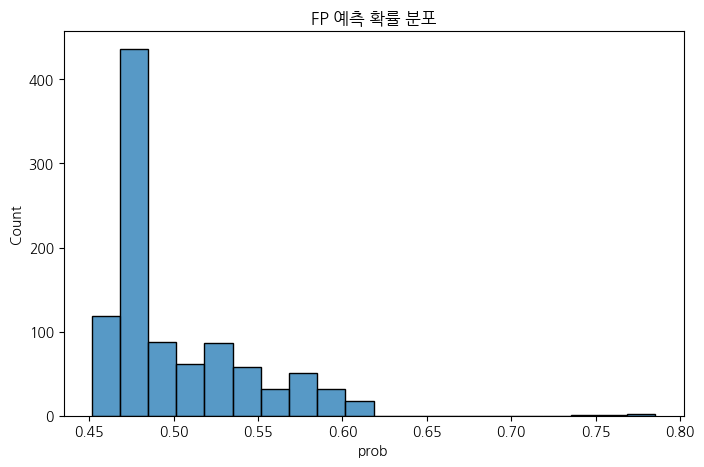

In [ ]:
# =========================
# 6. FP 확률 분포 확인
# =========================

display(FP['prob'].describe().round(3))

plt.figure(figsize=(8, 5))

sns.histplot(
    data=FP,
    x='prob',
    bins=20
)

plt.title('FP 예측 확률 분포')
plt.show()

## Threshold 부근 FP 비율 확인

FP 중에서 현재 Threshold(0.45) 근처에 위치한 사례의 비율을 계산하였다.

Threshold 부근에 FP가 집중되어 있다면

Threshold를 소폭 조정하는 것만으로도
FP를 감소시켜 Precision을 향상시킬 가능성이 있다.


In [ ]:
# =========================
# 7. FP가 threshold 근처인지 확인
# =========================

near_threshold_fp = FP[
    (FP['prob'] >= best_threshold) &
    (FP['prob'] < best_threshold + 0.1)
]

print('전체 FP 수:', len(FP))
print('threshold 근처 FP 수:', len(near_threshold_fp))
print('비율:', round(len(near_threshold_fp) / len(FP), 3))

전체 FP 수: 985
threshold 근처 FP 수: 848
비율: 0.861


## Threshold 최적화

Threshold를 0.10부터 0.90까지 탐색하여

- Precision
- Recall
- F1-score

변화를 비교하였다.

최종 Threshold는
F1-score가 가장 높은 값을 기준으로 선정하였다.

In [ ]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

threshold_results = []

for threshold in np.arange(0.45, 0.71, 0.01):

    y_pred = (y_test_proba >= threshold).astype(int)

    threshold_results.append({
        'threshold': round(threshold, 2),
        'accuracy': accuracy_score(y_test, y_pred),
        'precision': precision_score(y_test, y_pred, zero_division=0),
        'recall': recall_score(y_test, y_pred, zero_division=0),
        'f1': f1_score(y_test, y_pred, zero_division=0)
    })

threshold_result_df = pd.DataFrame(threshold_results)

display(threshold_result_df)

,threshold,accuracy,precision,recall,f1
0,0.45,0.425906,0.387819,0.910949,0.544028
1,0.46,0.442920,0.393822,0.893431,0.546673
2,0.47,0.473106,0.404580,0.851095,0.548448
3,0.48,0.569704,0.434954,0.483212,0.457815
4,0.49,0.579034,0.444293,0.477372,0.460239
5,0.50,0.594402,0.457680,0.426277,0.441421
6,0.51,0.606476,0.472881,0.407299,0.437647
7,0.52,0.610318,0.476636,0.372263,0.418033
8,0.53,0.625686,0.503667,0.300730,0.376600
9,0.54,0.630077,0.516035,0.258394,0.344358


In [ ]:
best = threshold_result_df.sort_values('f1', ascending=False).iloc[0]

display(best.to_frame().T)

,threshold,accuracy,precision,recall,f1,roc_auc
37,0.47,0.473106,0.40458,0.851095,0.548448,0.586151


In [ ]:
# 이전 결과
threshold	accuracy	precision	recall	f1	roc_auc
0	0.45	0.4259	0.3878	0.9109	0.544	0.5862

## Threshold 0.45와 0.47 비교

기존 Threshold(0.45)와
F1-score가 가장 높았던 Threshold(0.47)를 비교하였다.

Threshold 변경에 따라

- Precision
- Recall
- F1-score

가 어떻게 변화하는지 확인하고
최종 Threshold의 적절성을 평가하였다.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

thresholds = [0.45, 0.47]

result_list = []

for threshold in thresholds:

    y_pred = (y_test_proba >= threshold).astype(int)

    result_list.append({
        'Threshold': threshold,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'ROC_AUC': roc_auc_score(y_test, y_test_proba)
    })

result_df = pd.DataFrame(result_list)

print('성능 비교')
display(result_df.round(4))

성능 비교


,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC
0,0.45,0.4259,0.3878,0.9109,0.5440,0.5862
1,0.47,0.4731,0.4046,0.8511,0.5484,0.5862


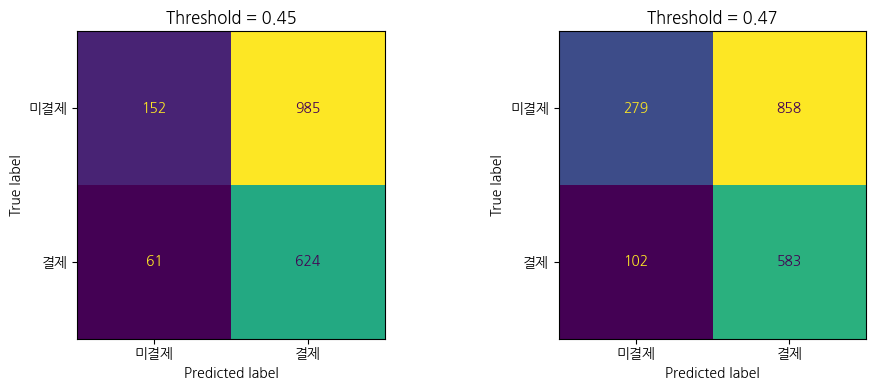

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, threshold in zip(axes, thresholds):

    y_pred = (y_test_proba >= threshold).astype(int)

    cm = confusion_matrix(y_test, y_pred)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['미결제', '결제']
    )

    disp.plot(
        ax=ax,
        values_format='d',
        colorbar=False
    )

    ax.set_title(f'Threshold = {threshold}')

plt.tight_layout()
plt.show()

## 분석 결과

FP와 TP의 Feature 분포는 매우 유사하였으며
현재 사용한 Feature만으로는 두 집단을 명확하게 구분하기 어려웠다.

또한 FP의 대부분이 Threshold 부근에 위치하여
Threshold 조정을 통해 Precision은 일부 향상되었으나
성능 개선 폭은 크지 않았다.

따라서 현재 모델의 한계는 Threshold보다
Feature의 구분력에 있으며,

향후에는 FP와 TP를 구분할 수 있는
추가적인 Feature Engineering이 성능 향상에 더 효과적일 것으로 판단된다.